In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset/sample_submission.csv
/kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset/train_metadata.csv
/kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset/test/images/0020cba7-1d58-4784-91f9-6fc47d9f2806.jpg
/kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset/test/images/003fae32-30d9-441b-8fcf-073fc04bf1d1.jpg
/kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset/test/images/0061307d-aad7-4d74-a501-ba708c8b1ac8.jpg
/kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset/test/images/006aa5af-5db6-413b-a60f-fcc6071ddc3c.jpg
/kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset/test/images/009a6a38-29a4-46d4-8ecc-905d776d924e.jpg
/kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset/test/images/00a24788-f2c0-4ff0-8b14-35a259208179.jpg
/kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset/test/images/00b3e968-9f14-48e1-94af-bed1a153f582.jpg
/kaggle/input/dataset

In [4]:
# ==============================================================================
# Model 3: DenseNet-121 Training & Auto-Ensemble Script for Kaggle GPU
# ==============================================================================
# DenseNet-121 uses dense connections where each layer receives feature maps
# from all preceding layers. This preserves fine micro-textural details.
# This script:
#   1. Trains DenseNet-121 on Fold 0 (directly comparable to EfficientNet-B3).
#   2. Tracks validation AUC-ROC and saves best weights to 'outputs/densenet_weights.pt'.
#   3. Runs inference on test images -> 'predictions_densenet.csv'.
#   4. If 'predictions.csv' (EfficientNet) exists, blends both into 'predictions_blended.csv'.

import subprocess
import sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm", "albumentations", "scikit-learn"])

import os
import time
import random
import cv2
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.metrics import roc_auc_score, f1_score
from sklearn.model_selection import StratifiedKFold

# 1. Reproducibility
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(42)

# 2. Locate Dataset
DATASET_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "train_metadata.csv" in files:
        DATASET_DIR = root
        break

if DATASET_DIR is None:
    raise FileNotFoundError("Could not find train_metadata.csv in /kaggle/input")

print(f"Dataset found at: {DATASET_DIR}")
train_meta_path = os.path.join(DATASET_DIR, "train_metadata.csv")
df = pd.read_csv(train_meta_path)

file_paths = []
for _, row in df.iterrows():
    sub = "real" if row["label"] == 0 else "fake"
    file_paths.append(os.path.join(DATASET_DIR, "train", sub, f"{row['image_id']}.jpg"))
df["file_path"] = file_paths

# Stratified 5-Fold split (Fold 0 = Validation)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
df["fold"] = -1
for fold, (train_idx, val_idx) in enumerate(skf.split(df, df["label"])):
    df.loc[val_idx, "fold"] = fold

train_df = df[df["fold"] != 0].reset_index(drop=True)
val_df = df[df["fold"] == 0].reset_index(drop=True)
print(f"Train samples: {len(train_df)} | Val samples: {len(val_df)}")

# 3. Augmentations
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transforms = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=15, border_mode=cv2.BORDER_CONSTANT, p=0.5),
    A.ImageCompression(p=0.4),
    A.GaussianBlur(blur_limit=(3, 5), p=0.3),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.4),
    A.CoarseDropout(max_holes=8, max_height=16, max_width=16, min_holes=1, min_height=8, min_width=8, fill_value=0, p=0.3),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

valid_transforms = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

class DeepfakeDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = cv2.imread(row["file_path"])
        if image is None:
            image = np.array(Image.open(row["file_path"]).convert("RGB"))
        else:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if self.transform:
            image = self.transform(image=image)["image"]

        label = torch.tensor([float(row["label"])], dtype=torch.float32)
        return image, label, str(row["image_id"])

train_loader = DataLoader(DeepfakeDataset(train_df, train_transforms), batch_size=32, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
val_loader = DataLoader(DeepfakeDataset(val_df, valid_transforms), batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# 4. DenseNet-121 Architecture
class DenseNetClassifier(nn.Module):
    def __init__(self, model_name="densenet121", pretrained=True, drop_rate=0.3):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, drop_rate=drop_rate)
        in_features = self.backbone.num_features  # 1024 for DenseNet121
        self.head = nn.Sequential(
            nn.Dropout(p=drop_rate),
            nn.Linear(in_features, 256),
            nn.LayerNorm(256),
            nn.SiLU(),
            nn.Dropout(p=drop_rate / 2.0),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.head(self.backbone(x))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
model = DenseNetClassifier("densenet121", pretrained=True).to(device)

# 5. Training Loop
EPOCHS = 10
LR = 3e-4

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == "cuda"))

best_auc = 0.0
best_thresh = 0.5
history = []
os.makedirs("outputs", exist_ok=True)

print("\nStarting DenseNet-121 Training on GPU...")
for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0.0
    for images, labels, _ in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [Train]"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
            logits = model(images)
            loss = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        train_loss += loss.item() * images.size(0)
    train_loss /= len(train_loader.dataset)

    model.eval()
    val_loss = 0.0
    val_targets, val_probs = [], []
    with torch.inference_mode():
        for images, labels, _ in tqdm(val_loader, desc=f"Epoch {epoch}/{EPOCHS} [Val]"):
            images, labels = images.to(device), labels.to(device)
            with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                logits = model(images)
                loss = criterion(logits, labels)
            val_loss += loss.item() * images.size(0)
            val_targets.extend(labels.cpu().numpy().flatten())
            val_probs.extend(torch.sigmoid(logits).cpu().numpy().flatten())
    val_loss /= len(val_loader.dataset)
    val_targets = np.array(val_targets)
    val_probs = np.nan_to_num(np.array(val_probs), nan=0.5)

    val_auc = roc_auc_score(val_targets, val_probs)
    cur_best_f1, cur_thresh = 0.0, 0.5
    for t in np.arange(0.1, 0.95, 0.05):
        f1 = f1_score(val_targets, (val_probs >= t).astype(int), zero_division=0)
        if f1 > cur_best_f1:
            cur_best_f1, cur_thresh = f1, t

    scheduler.step()
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f} | Val F1: {cur_best_f1:.4f} (thresh={cur_thresh:.2f})")

    history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "val_auc": val_auc, "val_f1": cur_best_f1})

    if val_auc > best_auc:
        best_auc = val_auc
        best_thresh = cur_thresh
        torch.save({
            "model_state_dict": model.state_dict(),
            "best_auc": best_auc,
            "best_threshold": best_thresh,
            "model_name": "densenet121"
        }, "outputs/densenet_weights.pt")
        print(f"  --> [*] Saved new best model to outputs/densenet_weights.pt (AUC: {best_auc:.4f})")

print(f"\nDenseNet-121 Training Complete! Best Validation AUC: {best_auc:.4f}")

# 6. Automatic Test Inference
TEST_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "test" in root and "images" in root:
        TEST_DIR = root
        break

if TEST_DIR:
    print(f"\nRunning test inference on {TEST_DIR}...")
    test_files = sorted([os.path.join(TEST_DIR, f) for f in os.listdir(TEST_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
    
    class TestDataset(Dataset):
        def __init__(self, file_paths):
            self.file_paths = file_paths
        def __len__(self):
            return len(self.file_paths)
        def __getitem__(self, idx):
            path = self.file_paths[idx]
            image_id = os.path.splitext(os.path.basename(path))[0]
            with Image.open(path) as img:
                arr = np.array(img.convert("RGB"), dtype=np.float32) / 255.0
            arr = (arr - np.array(IMAGENET_MEAN, dtype=np.float32)) / np.array(IMAGENET_STD, dtype=np.float32)
            tensor = torch.from_numpy(arr).permute(2, 0, 1).float()
            return tensor, image_id

    test_loader = DataLoader(TestDataset(test_files), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
    
    # Load best checkpoint
    ckpt = torch.load("outputs/densenet_weights.pt", map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()

    all_ids, all_probs = [], []
    with torch.inference_mode():
        for images, ids in tqdm(test_loader, desc="DenseNet Inference (TTA)"):
            images = images.to(device)
            with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                # Pass 1: Original
                p1 = torch.sigmoid(model(images)).squeeze(-1)
                # Pass 2: Flipped (TTA)
                p2 = torch.sigmoid(model(torch.flip(images, dims=[-1]))).squeeze(-1)
                probs = (p1 + p2) / 2.0
            all_ids.extend(ids)
            all_probs.extend(probs.cpu().numpy().tolist())

    densenet_probs = np.clip(np.array(all_probs), 0.0, 1.0)
    df_densenet = pd.DataFrame({
        "image_id": all_ids,
        "label": (densenet_probs >= best_thresh).astype(int),
        "confidence": np.round(densenet_probs, 4)
    })
    df_densenet.to_csv("predictions_densenet.csv", index=False)
    print("Saved predictions_densenet.csv successfully!")

    # 7. Auto-Blend with EfficientNet-B3 (if existing predictions.csv found)
    if os.path.exists("predictions.csv"):
        print("\nFound existing EfficientNet predictions.csv! Generating blended ensemble...")
        df_eff = pd.read_csv("predictions.csv")
        eff_probs = df_eff["confidence"].values
        
        # Weighted blend (55% EfficientNet [0.9142] + 45% DenseNet)
        blended_probs = 0.55 * eff_probs + 0.45 * densenet_probs
        blended_probs = np.clip(blended_probs, 0.0, 1.0)
        df_blend = pd.DataFrame({
            "image_id": all_ids,
            "label": (blended_probs >= 0.50).astype(int),
            "confidence": np.round(blended_probs, 4)
        })
        df_blend.to_csv("predictions_blended.csv", index=False)
        print("Successfully generated 'predictions_blended.csv' (55% EfficientNet + 45% DenseNet)!")



Dataset found at: /kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset
Train samples: 5600 | Val samples: 1400
Using device: cuda


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_49/2319993334.py:90: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, min_height, min_width, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=16, max_width=16, min_holes=1, min_height=8, min_width=8, fill_value=0, p=0.3),



Starting DenseNet-121 Training on GPU...


Epoch 1/10 [Train]:   0%|          | 0/175 [00:00<?, ?it/s]

Epoch 1/10 [Val]:   0%|          | 0/44 [00:00<?, ?it/s]

Epoch [01/10] Train Loss: 0.5685 | Val Loss: 0.4387 | Val AUC: 0.8781 | Val F1: 0.8220 (thresh=0.25)
  --> [*] Saved new best model to outputs/densenet_weights.pt (AUC: 0.8781)


... (26 outputs left out)

Epoch 10/10 [Val]:   0%|          | 0/44 [00:00<?, ?it/s]

Epoch [10/10] Train Loss: 0.1742 | Val Loss: 0.4199 | Val AUC: 0.9071 | Val F1: 0.8689 (thresh=0.60)

DenseNet-121 Training Complete! Best Validation AUC: 0.9172

Running test inference on /kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset/test/images...


DenseNet Inference (TTA):   0%|          | 0/47 [00:00<?, ?it/s]

Saved predictions_densenet.csv successfully!


In [5]:
# ==============================================================================
# OPTION 1: EVALUATE ENSEMBLE BLEND ON VALIDATION SET (1,400 SAMPLES)
# ==============================================================================
import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score, f1_score
from tqdm.auto import tqdm

# 1. Dataset & Loader
val_dataset = DeepfakeDataset(val_df, valid_transforms)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Get EfficientNet-B3 Validation Probabilities
eff_model = DeepfakeClassifier("efficientnet_b3", pretrained=False).to(device)
eff_ckpt = torch.load("outputs/model_weights.pt", map_location=device, weights_only=False)
eff_model.load_state_dict(eff_ckpt["model_state_dict"])
eff_model.eval()

eff_val_probs, val_targets = [], []
with torch.inference_mode():
    for images, labels, _ in tqdm(val_loader, desc="EfficientNet Validation"):
        images = images.to(device)
        with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
            probs = torch.sigmoid(eff_model(images)).squeeze(-1)
        eff_val_probs.extend(probs.cpu().numpy().tolist())
        val_targets.extend(labels.cpu().numpy().flatten())

# 3. Get DenseNet-121 Validation Probabilities
dense_model = DenseNetClassifier("densenet121", pretrained=False).to(device)
dense_ckpt = torch.load("outputs/densenet_weights.pt", map_location=device, weights_only=False)
dense_model.load_state_dict(dense_ckpt["model_state_dict"])
dense_model.eval()

dense_val_probs = []
with torch.inference_mode():
    for images, labels, _ in tqdm(val_loader, desc="DenseNet Validation"):
        images = images.to(device)
        with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
            probs = torch.sigmoid(dense_model(images)).squeeze(-1)
        dense_val_probs.extend(probs.cpu().numpy().tolist())

eff_val_probs = np.array(eff_val_probs)
dense_val_probs = np.array(dense_val_probs)
val_targets = np.array(val_targets)

# 4. Grid Search Optimal Blend Weights
print("\n--- Model AUC Comparison ---")
auc_eff = roc_auc_score(val_targets, eff_val_probs)
auc_dense = roc_auc_score(val_targets, dense_val_probs)
print(f"EfficientNet-B3 Single AUC : {auc_eff:.4f}")
print(f"DenseNet-121    Single AUC : {auc_dense:.4f}")

best_blend_auc, best_w = 0.0, 0.5
for w_dense in np.linspace(0.1, 0.9, 17):
    w_eff = 1.0 - w_dense
    blended = w_dense * dense_val_probs + w_eff * eff_val_probs
    auc = roc_auc_score(val_targets, blended)
    if auc > best_blend_auc:
        best_blend_auc = auc
        best_w = w_dense

print(f"\n[*] OPTION 1 ENSEMBLE BLEND AUC: {best_blend_auc:.4f}")
print(f"[*] Optimal Blend: {best_w:.2f} * DenseNet + {1-best_w:.2f} * EfficientNet")

NameError: name 'DeepfakeClassifier' is not defined

In [ ]:
# ==============================================================================
# OPTION 2: SWIN VISION TRANSFORMER (Swin-Tiny) FOR DEEPFAKE DETECTION
# ==============================================================================
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm", "albumentations", "scikit-learn"])

import os, time, random, cv2
import numpy as np, pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.metrics import roc_auc_score, f1_score
from sklearn.model_selection import StratifiedKFold

# 1. Reproducibility
def seed_everything(seed=42):
    random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
seed_everything(42)

# 2. Data Preparation
DATASET_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "train_metadata.csv" in files: DATASET_DIR = root; break
train_meta_path = os.path.join(DATASET_DIR, "train_metadata.csv")
df = pd.read_csv(train_meta_path)
df["file_path"] = [os.path.join(DATASET_DIR, "train", "real" if r["label"] == 0 else "fake", f"{r['image_id']}.jpg") for _, r in df.iterrows()]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
df["fold"] = -1
for fold, (train_idx, val_idx) in enumerate(skf.split(df, df["label"])): df.loc[val_idx, "fold"] = fold

train_df = df[df["fold"] != 0].reset_index(drop=True)
val_df = df[df["fold"] == 0].reset_index(drop=True)

# 3. Augmentations
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
train_transforms = A.Compose([
    A.Resize(224, 224), A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=15, border_mode=cv2.BORDER_CONSTANT, p=0.5),
    A.ImageCompression(p=0.4), A.GaussianBlur(blur_limit=(3, 5), p=0.3),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.4),
    A.CoarseDropout(max_holes=8, max_height=16, max_width=16, min_holes=1, min_height=8, min_width=8, fill_value=0, p=0.3),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2(),
])
valid_transforms = A.Compose([A.Resize(224, 224), A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2()])

class DeepfakeDataset(Dataset):
    def __init__(self, df, transform=None): self.df = df.reset_index(drop=True); self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row["file_path"])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img is not None else np.array(Image.open(row["file_path"]).convert("RGB"))
        if self.transform: img = self.transform(image=img)["image"]
        return img, torch.tensor([float(row["label"])], dtype=torch.float32), str(row["image_id"])

train_loader = DataLoader(DeepfakeDataset(train_df, train_transforms), batch_size=32, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
val_loader = DataLoader(DeepfakeDataset(val_df, valid_transforms), batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# 4. Swin Transformer Model
class SwinClassifier(nn.Module):
    def __init__(self, model_name="swin_tiny_patch4_window7_224", pretrained=True, drop_rate=0.3):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, drop_rate=drop_rate)
        in_features = self.backbone.num_features # 768
        self.head = nn.Sequential(
            nn.Dropout(p=drop_rate),
            nn.Linear(in_features, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(p=drop_rate / 2.0),
            nn.Linear(256, 1)
        )
    def forward(self, x): return self.head(self.backbone(x))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SwinClassifier().to(device)

# 5. Training
EPOCHS = 10
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1.5e-4, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == "cuda"))

best_auc = 0.0
print("\nStarting Swin Transformer Training on GPU...")
for epoch in range(1, EPOCHS + 1):
    model.train(); train_loss = 0.0
    for images, labels, _ in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [Train]"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
            loss = criterion(model(images), labels)
        scaler.scale(loss).backward(); scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update()
        train_loss += loss.item() * images.size(0)
    train_loss /= len(train_loader.dataset)

    model.eval(); val_loss = 0.0; val_targets, val_probs = [], []
    with torch.inference_mode():
        for images, labels, _ in tqdm(val_loader, desc=f"Epoch {epoch}/{EPOCHS} [Val]"):
            images, labels = images.to(device), labels.to(device)
            with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                logits = model(images)
                loss = criterion(logits, labels)
            val_loss += loss.item() * images.size(0)
            val_targets.extend(labels.cpu().numpy().flatten())
            val_probs.extend(torch.sigmoid(logits).cpu().numpy().flatten())
    val_loss /= len(val_loader.dataset)
    val_probs = np.nan_to_num(np.array(val_probs), nan=0.5)
    val_auc = roc_auc_score(np.array(val_targets), val_probs)
    scheduler.step()
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f}")
    if val_auc > best_auc:
        best_auc = val_auc
        torch.save({"model_state_dict": model.state_dict(), "best_auc": best_auc, "model_name": "swin_tiny"}, "outputs/swin_weights.pt")
        print(f"  --> [*] Saved new best Swin model (AUC: {best_auc:.4f})")

print(f"\n[*] OPTION 2 SWIN TRANSFORMER BEST AUC: {best_auc:.4f}")

In [ ]:
# ==============================================================================
# OPTION 3: DENSENET-121 WITH FOCAL LOSS (Downweights easy samples, maximizes AUC)
# ==============================================================================
class BinaryFocalLoss(nn.Module):
    def __init__(self, alpha=0.5, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):
        p = torch.sigmoid(logits)
        ce_loss = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        p_t = p * targets + (1 - p) * (1 - targets)
        loss = ce_loss * ((1 - p_t) ** self.gamma)
        if self.alpha >= 0:
            alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
            loss = alpha_t * loss
        return loss.mean()

focal_model = DenseNetClassifier("densenet121", pretrained=True).to(device)
focal_criterion = BinaryFocalLoss(alpha=0.5, gamma=2.0)
focal_optimizer = torch.optim.AdamW(focal_model.parameters(), lr=3e-4, weight_decay=1e-2)
focal_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(focal_optimizer, T_max=10, eta_min=1e-6)
focal_scaler = torch.amp.GradScaler('cuda', enabled=(device.type == "cuda"))

best_focal_auc = 0.0
print("\nStarting DenseNet-121 Training with FOCAL LOSS on GPU...")
for epoch in range(1, 11):
    focal_model.train()
    for images, labels, _ in tqdm(train_loader, desc=f"Epoch {epoch}/10 [Train]"):
        images, labels = images.to(device), labels.to(device)
        focal_optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
            loss = focal_criterion(focal_model(images), labels)
        focal_scaler.scale(loss).backward(); focal_scaler.unscale_(focal_optimizer)
        torch.nn.utils.clip_grad_norm_(focal_model.parameters(), 1.0)
        focal_scaler.step(focal_optimizer); focal_scaler.update()

    focal_model.eval(); val_targets, val_probs = [], []
    with torch.inference_mode():
        for images, labels, _ in tqdm(val_loader, desc=f"Epoch {epoch}/10 [Val]"):
            images, labels = images.to(device), labels.to(device)
            with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                logits = focal_model(images)
            val_targets.extend(labels.cpu().numpy().flatten())
            val_probs.extend(torch.sigmoid(logits).cpu().numpy().flatten())
    val_probs = np.nan_to_num(np.array(val_probs), nan=0.5)
    focal_auc = roc_auc_score(np.array(val_targets), val_probs)
    focal_scheduler.step()
    print(f"Epoch [{epoch:02d}/10] Val AUC with Focal Loss: {focal_auc:.4f}")
    if focal_auc > best_focal_auc:
        best_focal_auc = focal_auc
        torch.save({"model_state_dict": focal_model.state_dict(), "best_auc": best_focal_auc}, "outputs/densenet_focal_weights.pt")
        print(f"  --> [*] Saved new best Focal Loss model (AUC: {best_focal_auc:.4f})")

print(f"\n[*] OPTION 3 DENSENET FOCAL LOSS BEST AUC: {best_focal_auc:.4f}")

In [ ]:
# ==============================================================================
# OPTION 4: 4-PASS TTA EVALUATION (Original, Flip, Brightness+, Flip+Brightness+)
# ==============================================================================
ckpt = torch.load("outputs/densenet_weights.pt", map_location=device, weights_only=False)
model = DenseNetClassifier("densenet121", pretrained=False).to(device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

tta_probs, val_targets = [], []
with torch.inference_mode():
    for images, labels, _ in tqdm(val_loader, desc="Running 4-Pass TTA"):
        images = images.to(device)
        with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
            # Pass 1: Original
            p1 = torch.sigmoid(model(images)).squeeze(-1)
            # Pass 2: Horizontal Flip
            p2 = torch.sigmoid(model(torch.flip(images, dims=[-1]))).squeeze(-1)
            # Pass 3: Slight Brightness shift (+5%)
            p3 = torch.sigmoid(model(images * 1.05)).squeeze(-1)
            # Pass 4: Flipped + Brightness shift
            p4 = torch.sigmoid(model(torch.flip(images, dims=[-1]) * 1.05)).squeeze(-1)
            
            p_tta = (p1 + p2 + p3 + p4) / 4.0

        tta_probs.extend(p_tta.cpu().numpy().tolist())
        val_targets.extend(labels.cpu().numpy().flatten())

tta_probs = np.nan_to_num(np.array(tta_probs), nan=0.5)
tta_auc = roc_auc_score(np.array(val_targets), tta_probs)

print(f"\nSingle-Pass DenseNet AUC : 0.9235")
print(f"[*] OPTION 4 (4-PASS TTA) AUC : {tta_auc:.4f}")

In [ ]:
# ==============================================================================
# FINAL STEP: CNN + VISION TRANSFORMER SUPER-ENSEMBLE (4-PASS TTA)
# ==============================================================================
import os, cv2, numpy as np, pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm
from sklearn.metrics import roc_auc_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running Super-Ensemble on: {device}")

# 1. Model Definitions
class DeepfakeClassifier(nn.Module):
    def __init__(self, model_name="efficientnet_b3"):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=False, num_classes=0)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(self.backbone.num_features, 256), nn.SiLU(), nn.Dropout(0.15), nn.Linear(256, 1))
    def forward(self, x): return self.head(self.backbone(x))

class DenseNetClassifier(nn.Module):
    def __init__(self, model_name="densenet121"):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=False, num_classes=0)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(self.backbone.num_features, 256), nn.LayerNorm(256), nn.SiLU(), nn.Dropout(0.15), nn.Linear(256, 1))
    def forward(self, x): return self.head(self.backbone(x))

class SwinClassifier(nn.Module):
    def __init__(self, model_name="swin_tiny_patch4_window7_224"):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=False, num_classes=0)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(self.backbone.num_features, 256), nn.LayerNorm(256), nn.GELU(), nn.Dropout(0.15), nn.Linear(256, 1))
    def forward(self, x): return self.head(self.backbone(x))

# 2. Load Checkpoints
m_eff = DeepfakeClassifier().to(device)
m_eff.load_state_dict(torch.load("outputs/model_weights.pt", map_location=device, weights_only=False)["model_state_dict"])
m_eff.eval()

m_dense = DenseNetClassifier().to(device)
m_dense.load_state_dict(torch.load("outputs/densenet_weights.pt", map_location=device, weights_only=False)["model_state_dict"])
m_dense.eval()

m_swin = SwinClassifier().to(device)
m_swin.load_state_dict(torch.load("outputs/swin_weights.pt", map_location=device, weights_only=False)["model_state_dict"])
m_swin.eval()

print("All 3 models loaded successfully!")

# 3. 4-Pass TTA Predictor Helper
def predict_tta(model, images):
    with torch.amp.autocast('cuda'):
        p1 = torch.sigmoid(model(images)).squeeze(-1)
        p2 = torch.sigmoid(model(torch.flip(images, dims=[-1]))).squeeze(-1)
        p3 = torch.sigmoid(model(images * 1.05)).squeeze(-1)
        p4 = torch.sigmoid(model(torch.flip(images, dims=[-1]) * 1.05)).squeeze(-1)
    return (p1 + p2 + p3 + p4) / 4.0

# 4. Validation Set Evaluation
val_dataset = DeepfakeDataset(val_df, valid_transforms)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

p_eff_val, p_dense_val, p_swin_val, y_true = [], [], [], []
with torch.inference_mode():
    for images, labels, _ in tqdm(val_loader, desc="Validating Ensemble"):
        images = images.to(device)
        p_eff_val.extend(predict_tta(m_eff, images).cpu().numpy().tolist())
        p_dense_val.extend(predict_tta(m_dense, images).cpu().numpy().tolist())
        p_swin_val.extend(predict_tta(m_swin, images).cpu().numpy().tolist())
        y_true.extend(labels.numpy().flatten())

p_eff_val, p_dense_val, p_swin_val = np.array(p_eff_val), np.array(p_dense_val), np.array(p_swin_val)
y_true = np.array(y_true)

# Weighted Ensemble: 45% Swin (0.9284) + 40% DenseNet (0.9282) + 15% EffNet (0.9142)
p_ensemble_val = 0.45 * p_swin_val + 0.40 * p_dense_val + 0.15 * p_eff_val
super_auc = roc_auc_score(y_true, p_ensemble_val)

print("\n" + "=" * 60)
print(f"EfficientNet-B3 Val AUC : {roc_auc_score(y_true, p_eff_val):.4f}")
print(f"DenseNet-121    Val AUC : {roc_auc_score(y_true, p_dense_val):.4f}")
print(f"Swin-Tiny (ViT) Val AUC : {roc_auc_score(y_true, p_swin_val):.4f}")
print(f"[*] SUPER-ENSEMBLE VAL AUC : {super_auc:.4f}")
print("=" * 60)

# 5. Generate Final Test Predictions (3,000 images)
TEST_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "test" in root and "images" in root: TEST_DIR = root; break

test_files = sorted([os.path.join(TEST_DIR, f) for f in os.listdir(TEST_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])

class FinalTestDataset(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        path = self.paths[idx]
        img = Image.open(path).convert("RGB")
        arr = (np.array(img, dtype=np.float32) / 255.0 - np.array([0.485, 0.456, 0.406], dtype=np.float32)) / np.array([0.229, 0.224, 0.225], dtype=np.float32)
        return torch.from_numpy(arr).permute(2, 0, 1).float(), os.path.splitext(os.path.basename(path))[0]

test_loader = DataLoader(FinalTestDataset(test_files), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

test_eff, test_dense, test_swin, test_ids = [], [], [], []
with torch.inference_mode():
    for images, ids in tqdm(test_loader, desc="Generating Super-Ensemble Predictions"):
        images = images.to(device)
        test_eff.extend(predict_tta(m_eff, images).cpu().numpy().tolist())
        test_dense.extend(predict_tta(m_dense, images).cpu().numpy().tolist())
        test_swin.extend(predict_tta(m_swin, images).cpu().numpy().tolist())
        test_ids.extend(ids)

test_final_probs = 0.45 * np.array(test_swin) + 0.40 * np.array(test_dense) + 0.15 * np.array(test_eff)
test_final_probs = np.clip(test_final_probs, 0.0, 1.0)
test_labels = (test_final_probs >= 0.50).astype(int)

final_sub = pd.DataFrame({
    "image_id": test_ids,
    "label": test_labels,
    "confidence": np.round(test_final_probs, 4)
})

final_sub.to_csv("predictions.csv", index=False)
print(f"\nFinal Super-Ensemble predictions saved to 'predictions.csv' ({len(final_sub)} rows)!")
print(f"Class Distribution: {final_sub['label'].value_counts().to_dict()}")

In [ ]:
# ==============================================================================
# 2-MODEL SUPER-ENSEMBLE (Swin ViT [0.9284] + DenseNet [0.9282])
# ==============================================================================
import os, cv2, numpy as np, pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm
from sklearn.metrics import roc_auc_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Models
class DenseNetClassifier(nn.Module):
    def __init__(self, model_name="densenet121"):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=False, num_classes=0)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(self.backbone.num_features, 256), nn.LayerNorm(256), nn.SiLU(), nn.Dropout(0.15), nn.Linear(256, 1))
    def forward(self, x): return self.head(self.backbone(x))

class SwinClassifier(nn.Module):
    def __init__(self, model_name="swin_tiny_patch4_window7_224"):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=False, num_classes=0)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(self.backbone.num_features, 256), nn.LayerNorm(256), nn.GELU(), nn.Dropout(0.15), nn.Linear(256, 1))
    def forward(self, x): return self.head(self.backbone(x))

# 2. Load Weights (checks both outputs/ and /kaggle/input/)
def find_weight(filename):
    for root, dirs, files in os.walk("/kaggle"):
        if filename in files: return os.path.join(root, filename)
    raise FileNotFoundError(f"Could not find {filename}")

dense_path = find_weight("densenet_weights.pt")
swin_path = find_weight("swin_weights.pt")

m_dense = DenseNetClassifier().to(device)
m_dense.load_state_dict(torch.load(dense_path, map_location=device, weights_only=False)["model_state_dict"])
m_dense.eval()

m_swin = SwinClassifier().to(device)
m_swin.load_state_dict(torch.load(swin_path, map_location=device, weights_only=False)["model_state_dict"])
m_swin.eval()

print("Loaded Swin & DenseNet successfully!")

# 3. 4-Pass TTA
def predict_tta(model, images):
    with torch.amp.autocast('cuda'):
        p1 = torch.sigmoid(model(images)).squeeze(-1)
        p2 = torch.sigmoid(model(torch.flip(images, dims=[-1]))).squeeze(-1)
        p3 = torch.sigmoid(model(images * 1.05)).squeeze(-1)
        p4 = torch.sigmoid(model(torch.flip(images, dims=[-1]) * 1.05)).squeeze(-1)
    return (p1 + p2 + p3 + p4) / 4.0

# 4. Validation AUC
val_dataset = DeepfakeDataset(val_df, valid_transforms)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

p_dense_val, p_swin_val, y_true = [], [], []
with torch.inference_mode():
    for images, labels, _ in tqdm(val_loader, desc="Validating"):
        images = images.to(device)
        p_dense_val.extend(predict_tta(m_dense, images).cpu().numpy().tolist())
        p_swin_val.extend(predict_tta(m_swin, images).cpu().numpy().tolist())
        y_true.extend(labels.numpy().flatten())

p_dense_val = np.array(p_dense_val)
p_swin_val = np.array(p_swin_val)
y_true = np.array(y_true)

# 50/50 blend between ViT and CNN
p_blend = 0.52 * p_swin_val + 0.48 * p_dense_val
blend_auc = roc_auc_score(y_true, p_blend)

print("\n" + "=" * 55)
print(f"DenseNet-121 (CNN) Val AUC : {roc_auc_score(y_true, p_dense_val):.4f}")
print(f"Swin-Tiny    (ViT) Val AUC : {roc_auc_score(y_true, p_swin_val):.4f}")
print(f"[*] SWIN + DENSENET BLEND AUC : {blend_auc:.4f}")
print("=" * 55)

# 5. Predict on Test Set (3,000 images)
TEST_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "test" in root and "images" in root: TEST_DIR = root; break

test_files = sorted([os.path.join(TEST_DIR, f) for f in os.listdir(TEST_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])

class FinalTestDataset(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        path = self.paths[idx]
        img = Image.open(path).convert("RGB")
        arr = (np.array(img, dtype=np.float32) / 255.0 - np.array([0.485, 0.456, 0.406], dtype=np.float32)) / np.array([0.229, 0.224, 0.225], dtype=np.float32)
        return torch.from_numpy(arr).permute(2, 0, 1).float(), os.path.splitext(os.path.basename(path))[0]

test_loader = DataLoader(FinalTestDataset(test_files), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

test_dense, test_swin, test_ids = [], [], []
with torch.inference_mode():
    for images, ids in tqdm(test_loader, desc="Generating Test Predictions"):
        images = images.to(device)
        test_dense.extend(predict_tta(m_dense, images).cpu().numpy().tolist())
        test_swin.extend(predict_tta(m_swin, images).cpu().numpy().tolist())
        test_ids.extend(ids)

test_final_probs = 0.52 * np.array(test_swin) + 0.48 * np.array(test_dense)
test_final_probs = np.clip(test_final_probs, 0.0, 1.0)

final_sub = pd.DataFrame({
    "image_id": test_ids,
    "label": (test_final_probs >= 0.50).astype(int),
    "confidence": np.round(test_final_probs, 4)
})
final_sub.to_csv("predictions.csv", index=False)
print(f"\nFinal predictions successfully saved to 'predictions.csv' ({len(final_sub)} rows)!")

In [1]:
import numpy as np
K = np.array([[1,0,-1],[2,0,-2],[1,0,-1]])
U, S, Vt = np.linalg.svd(K)
print(S)  # [~3.46, 0, 0] → rank 1
a = U[:,0] * np.sqrt(S[0])   # vertical 1D kernel
b = Vt[0,:] * np.sqrt(S[0])  # horizontal 1D kernel
print(np.allclose(np.outer(a, b), K))  # True

[3.46410162e+00 4.34470263e-16 0.00000000e+00]
True


In [2]:
# ==============================================================================
# ULTIMATE CHAMPIONSHIP DEEPFAKE PIPELINE (ALL TECHNIQUES COMBINED)
# ==============================================================================
# Features:
#   1. SRM Forensic Noise Filter Layer (detects GAN synthesis noise)
#   2. DenseNet-121 (Local boundary & texture modeling)
#   3. Swin-Tiny Vision Transformer (Global anatomical attention)
#   4. 4-Pass Test-Time Augmentation (TTA)
#   5. Rank Averaging (Optimizes Area Under ROC curve mathematically)
# ==============================================================================

import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm", "albumentations", "scikit-learn", "scipy"])

import os, time, random, cv2
import numpy as np, pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from scipy.stats import rankdata

import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.metrics import roc_auc_score, f1_score
from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------------------------
# 1. SETUP & REPRODUCIBILITY
# ------------------------------------------------------------------------------
def seed_everything(seed=42):
    random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
seed_everything(42)

os.makedirs("outputs", exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[*] Compute Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# ------------------------------------------------------------------------------
# 2. DATASET PREPARATION & 5-FOLD STRATIFICATION
# ------------------------------------------------------------------------------
DATASET_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "train_metadata.csv" in files: DATASET_DIR = root; break

if DATASET_DIR is None:
    raise FileNotFoundError("Could not find train_metadata.csv in /kaggle/input!")

print(f"[*] Dataset located at: {DATASET_DIR}")
train_meta = pd.read_csv(os.path.join(DATASET_DIR, "train_metadata.csv"))
train_meta["file_path"] = [os.path.join(DATASET_DIR, "train", "real" if r["label"] == 0 else "fake", f"{r['image_id']}.jpg") for _, r in train_meta.iterrows()]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_meta["fold"] = -1
for fold, (train_idx, val_idx) in enumerate(skf.split(train_meta, train_meta["label"])):
    train_meta.loc[val_idx, "fold"] = fold

train_df = train_meta[train_meta["fold"] != 0].reset_index(drop=True)
val_df = train_meta[train_meta["fold"] == 0].reset_index(drop=True)
print(f"[*] Splits: Train = {len(train_df)} | Holdout Validation = {len(val_df)}")

# ------------------------------------------------------------------------------
# 3. SRM FORENSIC FILTER LAYER (HIGH-PASS RESIDUALS)
# ------------------------------------------------------------------------------
class SRMConv2d(nn.Module):
    """Spatial Rich Model (SRM) High-Pass Filter: extracts noise residuals & GAN fingerprints."""
    def __init__(self):
        super().__init__()
        srm_kernel = np.array([
            [[-1, 2, -2, 2, -1], [2, -6, 8, -6, 2], [-2, 8, -12, 8, -2], [2, -6, 8, -6, 2], [-1, 2, -2, 2, -1]],
            [[0, 0, 0, 0, 0], [0, -1, 2, -1, 0], [0, 2, -4, 2, 0], [0, -1, 2, -1, 0], [0, 0, 0, 0, 0]],
            [[0, 0, 0, 0, 0], [0, 0, -1, 0, 0], [0, -1, 4, -1, 0], [0, 0, -1, 0, 0], [0, 0, 0, 0, 0]]
        ], dtype=np.float32) / 12.0

        self.conv = nn.Conv2d(1, 3, kernel_size=5, stride=1, padding=2, bias=False)
        self.conv.weight = nn.Parameter(torch.from_numpy(srm_kernel).unsqueeze(1), requires_grad=False)

    def forward(self, x):
        gray = 0.299 * x[:, 0:1, :, :] + 0.587 * x[:, 1:2, :, :] + 0.114 * x[:, 2:3, :, :]
        return self.conv(gray)

# ------------------------------------------------------------------------------
# 4. DATA AUGMENTATIONS & LOADERS
# ------------------------------------------------------------------------------
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transforms = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=15, border_mode=cv2.BORDER_CONSTANT, p=0.5),
    A.ImageCompression(p=0.4),
    A.GaussianBlur(blur_limit=(3, 5), p=0.3),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.4),
    A.CoarseDropout(max_holes=8, max_height=16, max_width=16, min_holes=1, min_height=8, min_width=8, fill_value=0, p=0.3),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

valid_transforms = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

class DeepfakeDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row["file_path"])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img is not None else np.array(Image.open(row["file_path"]).convert("RGB"))
        if self.transform: img = self.transform(image=img)["image"]
        return img, torch.tensor([float(row["label"])], dtype=torch.float32), str(row["image_id"])

train_loader = DataLoader(DeepfakeDataset(train_df, train_transforms), batch_size=32, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
val_loader = DataLoader(DeepfakeDataset(val_df, valid_transforms), batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# ------------------------------------------------------------------------------
# 5. MODEL ARCHITECTURES
# ------------------------------------------------------------------------------
class DenseNetClassifier(nn.Module):
    def __init__(self, model_name="densenet121", pretrained=True, drop_rate=0.3):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, drop_rate=drop_rate)
        self.head = nn.Sequential(
            nn.Dropout(p=drop_rate),
            nn.Linear(self.backbone.num_features, 256),
            nn.LayerNorm(256),
            nn.SiLU(),
            nn.Dropout(p=drop_rate / 2.0),
            nn.Linear(256, 1)
        )
    def forward(self, x): return self.head(self.backbone(x))

class SwinClassifier(nn.Module):
    def __init__(self, model_name="swin_tiny_patch4_window7_224", pretrained=True, drop_rate=0.3):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, drop_rate=drop_rate)
        self.head = nn.Sequential(
            nn.Dropout(p=drop_rate),
            nn.Linear(self.backbone.num_features, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(p=drop_rate / 2.0),
            nn.Linear(256, 1)
        )
    def forward(self, x): return self.head(self.backbone(x))

# ------------------------------------------------------------------------------
# 6. UNIVERSAL TRAINING ENGINE
# ------------------------------------------------------------------------------
def train_model(model, name, weights_path, epochs=10, lr=3e-4):
    print("\n" + "=" * 65)
    print(f"  TRAINING {name.upper()} (10 EPOCHS)")
    print("=" * 65)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda', enabled=(device.type == "cuda"))
    best_auc = 0.0

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss = 0.0
        for images, labels, _ in tqdm(train_loader, desc=f"[{name}] Epoch {epoch}/{epochs} (Train)", leave=False):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                loss = criterion(model(images), labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            train_loss += loss.item() * images.size(0)
        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        val_targets, val_probs = [], []
        with torch.inference_mode():
            for images, labels, _ in tqdm(val_loader, desc=f"[{name}] Epoch {epoch}/{epochs} (Val)", leave=False):
                images, labels = images.to(device), labels.to(device)
                with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                    logits = model(images)
                    loss = criterion(logits, labels)
                val_loss += loss.item() * images.size(0)
                val_targets.extend(labels.cpu().numpy().flatten())
                val_probs.extend(torch.sigmoid(logits).cpu().numpy().flatten())
        val_loss /= len(val_loader.dataset)
        val_probs = np.nan_to_num(np.array(val_probs), nan=0.5)
        val_auc = roc_auc_score(np.array(val_targets), val_probs)
        scheduler.step()

        print(f"Epoch [{epoch:02d}/{epochs:02d}] Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f}")
        if val_auc > best_auc:
            best_auc = val_auc
            torch.save({"model_state_dict": model.state_dict(), "best_auc": best_auc, "model_name": name}, weights_path)
            print(f"  --> [*] Saved new best {name} (AUC: {best_auc:.4f})")

    return best_auc

# ------------------------------------------------------------------------------
# 7. TRAIN DENSENET-121 (CNN) AND SWIN-TINY (ViT)
# ------------------------------------------------------------------------------
m_dense = DenseNetClassifier().to(device)
dense_auc = train_model(m_dense, "densenet121", "outputs/densenet_weights.pt", epochs=10, lr=3e-4)

m_swin = SwinClassifier().to(device)
swin_auc = train_model(m_swin, "swin_tiny", "outputs/swin_weights.pt", epochs=10, lr=1.5e-4)

# ------------------------------------------------------------------------------
# 8. 4-PASS TTA + PROBABILITY & RANK AVERAGING ON VALIDATION
# ------------------------------------------------------------------------------
print("\n" + "=" * 65)
print("  EVALUATING 4-PASS TTA & RANK AVERAGING ON VALIDATION SET")
print("=" * 65)

# Load best checkpoints
m_dense.load_state_dict(torch.load("outputs/densenet_weights.pt", map_location=device, weights_only=False)["model_state_dict"])
m_dense.eval()
m_swin.load_state_dict(torch.load("outputs/swin_weights.pt", map_location=device, weights_only=False)["model_state_dict"])
m_swin.eval()

def predict_4pass_tta(model, images):
    with torch.amp.autocast('cuda'):
        p1 = torch.sigmoid(model(images)).squeeze(-1)
        p2 = torch.sigmoid(model(torch.flip(images, dims=[-1]))).squeeze(-1)
        p3 = torch.sigmoid(model(images * 1.05)).squeeze(-1)
        p4 = torch.sigmoid(model(torch.flip(images, dims=[-1]) * 1.05)).squeeze(-1)
    return (p1 + p2 + p3 + p4) / 4.0

p_dense_val, p_swin_val, y_true = [], [], []
with torch.inference_mode():
    for images, labels, _ in tqdm(val_loader, desc="Running 4-Pass TTA Validation"):
        images = images.to(device)
        p_dense_val.extend(predict_4pass_tta(m_dense, images).cpu().numpy().tolist())
        p_swin_val.extend(predict_4pass_tta(m_swin, images).cpu().numpy().tolist())
        y_true.extend(labels.numpy().flatten())

p_dense_val = np.array(p_dense_val)
p_swin_val = np.array(p_swin_val)
y_true = np.array(y_true)

# Metric 1: Individual 4-Pass TTA
auc_dense_tta = roc_auc_score(y_true, p_dense_val)
auc_swin_tta = roc_auc_score(y_true, p_swin_val)

# Metric 2: Standard Probability Averaging
p_linear_blend = 0.50 * p_swin_val + 0.50 * p_dense_val
auc_linear = roc_auc_score(y_true, p_linear_blend)

# Metric 3: Rank Averaging (Normalizes distributions to [0, 1] ranks)
rank_dense = rankdata(p_dense_val) / len(p_dense_val)
rank_swin = rankdata(p_swin_val) / len(p_swin_val)
p_rank_blend = 0.50 * rank_swin + 0.50 * rank_dense
auc_rank = roc_auc_score(y_true, p_rank_blend)

print("\n" + "*" * 65)
print(f"[*] DenseNet-121 (4-Pass TTA) AUC  : {auc_dense_tta:.4f}")
print(f"[*] Swin-Tiny    (4-Pass TTA) AUC  : {auc_swin_tta:.4f}")
print(f"[*] Linear Probability Blend AUC   : {auc_linear:.4f}")
print(f"[*] >>> RANK-AVERAGED ENSEMBLE AUC: {auc_rank:.4f} <<<")
print("*" * 65)

# Choose best blending strategy
use_rank = (auc_rank >= auc_linear)
best_val_auc = max(auc_rank, auc_linear)
print(f"[*] Selected strategy for test set: {'Rank Averaging' if use_rank else 'Linear Blend'}")

# ------------------------------------------------------------------------------
# 9. GENERATE FINAL PREDICTIONS ON 3,000 TEST IMAGES
# ------------------------------------------------------------------------------
print("\n" + "=" * 65)
print("  GENERATING FINAL 3,000 TEST PREDICTIONS")
print("=" * 65)

TEST_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "test" in root and "images" in root: TEST_DIR = root; break

test_files = sorted([os.path.join(TEST_DIR, f) for f in os.listdir(TEST_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])

class TestDataset(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        path = self.paths[idx]
        img = Image.open(path).convert("RGB")
        arr = (np.array(img, dtype=np.float32) / 255.0 - np.array(IMAGENET_MEAN, dtype=np.float32)) / np.array(IMAGENET_STD, dtype=np.float32)
        return torch.from_numpy(arr).permute(2, 0, 1).float(), os.path.splitext(os.path.basename(path))[0]

test_loader = DataLoader(TestDataset(test_files), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

test_dense, test_swin, test_ids = [], [], []
with torch.inference_mode():
    for images, ids in tqdm(test_loader, desc="Predicting on Test Set"):
        images = images.to(device)
        test_dense.extend(predict_4pass_tta(m_dense, images).cpu().numpy().tolist())
        test_swin.extend(predict_4pass_tta(m_swin, images).cpu().numpy().tolist())
        test_ids.extend(ids)

test_dense = np.array(test_dense)
test_swin = np.array(test_swin)

if use_rank:
    r_dense = rankdata(test_dense) / len(test_dense)
    r_swin = rankdata(test_swin) / len(test_swin)
    final_conf = 0.50 * r_swin + 0.50 * r_dense
else:
    final_conf = 0.50 * test_swin + 0.50 * test_dense

final_conf = np.clip(final_conf, 0.001, 0.999)
final_labels = (final_conf >= 0.50).astype(int)

# Export predictions.csv
predictions_df = pd.DataFrame({
    "image_id": test_ids,
    "label": final_labels,
    "confidence": np.round(final_conf, 4)
})
predictions_df.to_csv("predictions.csv", index=False)
print(f"\n[+] 'predictions.csv' generated ({len(predictions_df)} rows)!")
print(f"[+] Class Breakdown:\n{predictions_df['label'].value_counts().to_dict()}")

# Save best weight as model_weights.pt
import shutil
best_weight_file = "outputs/swin_weights.pt" if auc_swin_tta >= auc_dense_tta else "outputs/densenet_weights.pt"
shutil.copyfile(best_weight_file, "outputs/model_weights.pt")
print(f"[+] Final submission weight saved to outputs/model_weights.pt (from {best_weight_file})")

print("\n" + "=" * 65)
print("  CHAMPIONSHIP PIPELINE COMPLETE!")
print(f"  Final Benchmark AUC: {best_val_auc:.4f}")
print("  Download 'predictions.csv' and 'outputs/model_weights.pt'")
print("=" * 65)

[*] Compute Device: cuda (Tesla T4)
[*] Dataset located at: /kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset
[*] Splits: Train = 5600 | Holdout Validation = 1400


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_50/3044372139.py:101: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, min_height, min_width, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=16, max_width=16, min_holes=1, min_height=8, min_width=8, fill_value=0, p=0.3),



  TRAINING DENSENET121 (10 EPOCHS)


[densenet121] Epoch 1/10 (Train):   0%|          | 0/175 [00:00<?, ?it/s]

[densenet121] Epoch 1/10 (Val):   0%|          | 0/44 [00:00<?, ?it/s]

Epoch [01/10] Train Loss: 0.5629 | Val Loss: 0.4621 | Val AUC: 0.8652
  --> [*] Saved new best densenet121 (AUC: 0.8652)


... (68 outputs left out)

Running 4-Pass TTA Validation:   0%|          | 0/44 [00:00<?, ?it/s]


*****************************************************************
[*] DenseNet-121 (4-Pass TTA) AUC  : 0.9232
[*] Swin-Tiny    (4-Pass TTA) AUC  : 0.9318
[*] Linear Probability Blend AUC   : 0.9327
[*] >>> RANK-AVERAGED ENSEMBLE AUC: 0.9336 <<<
*****************************************************************
[*] Selected strategy for test set: Rank Averaging

  GENERATING FINAL 3,000 TEST PREDICTIONS


Predicting on Test Set:   0%|          | 0/47 [00:00<?, ?it/s]


[+] 'predictions.csv' generated (3000 rows)!
[+] Class Breakdown:
{1: 1503, 0: 1497}
[+] Final submission weight saved to outputs/model_weights.pt (from outputs/swin_weights.pt)

  CHAMPIONSHIP PIPELINE COMPLETE!
  Final Benchmark AUC: 0.9336
  Download 'predictions.csv' and 'outputs/model_weights.pt'


In [9]:
# ==============================================================================
# DEEPFAKE ML HACKATHON — THE "HOLY TRINITY" 3-MODEL ENSEMBLE + 8-PASS TTA
# ==============================================================================
# Architecture Diversity (Maximum Orthogonality):
#   1. DenseNet-121   (Classic CNN: Micro-texture boundary seams & high-pass detail)
#   2. ConvNeXt-Tiny   (Modern Depthwise CNN: 7x7 inverted bottleneck structural patterns)
#   3. Swin-Tiny ViT   (Vision Transformer: Shifted-window global landmark attention)
#
# Inference Engine:
#   - 8-Pass Multi-Scale TTA (Original, Flip, Brightness, Contrast, Center-Zoom, & combinations)
#   - 3-Way Percentile Rank Averaging (ROC Curve Optimal Fusion)
# ==============================================================================

import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm", "albumentations", "scikit-learn", "scipy"])

import os, time, random, cv2, shutil
import numpy as np, pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from scipy.stats import rankdata

import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.metrics import roc_auc_score, f1_score
from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------------------------
# 1. SETUP & REPRODUCIBILITY
# ------------------------------------------------------------------------------
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(42)
os.makedirs("outputs", exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[*] Compute Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# ------------------------------------------------------------------------------
# 2. DATASET DISCOVERY & STRATIFIED 5-FOLD SPLIT
# ------------------------------------------------------------------------------
DATASET_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "train_metadata.csv" in files:
        DATASET_DIR = root
        break

if DATASET_DIR is None:
    raise FileNotFoundError("Could not find train_metadata.csv in /kaggle/input!")

print(f"[*] Dataset located at: {DATASET_DIR}")
train_meta = pd.read_csv(os.path.join(DATASET_DIR, "train_metadata.csv"))
train_meta["file_path"] = [
    os.path.join(DATASET_DIR, "train", "real" if r["label"] == 0 else "fake", f"{r['image_id']}.jpg")
    for _, r in train_meta.iterrows()
]

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
train_meta["fold"] = -1
for fold, (train_idx, val_idx) in enumerate(skf.split(train_meta, train_meta["label"])):
    train_meta.loc[val_idx, "fold"] = fold

train_df = train_meta[train_meta["fold"] != 0].reset_index(drop=True)
val_df = train_meta[train_meta["fold"] == 0].reset_index(drop=True)
print(f"[*] Dataset: Train={len(train_df)} | Holdout Validation={len(val_df)}")

# ------------------------------------------------------------------------------
# 3. AUGMENTATIONS & DATA LOADERS
# ------------------------------------------------------------------------------
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transforms = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=15, border_mode=cv2.BORDER_CONSTANT, p=0.5),
    A.ImageCompression(quality_lower=60, quality_upper=100, p=0.4),
    A.GaussianBlur(blur_limit=(3, 5), p=0.3),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.4),
    A.CoarseDropout(max_holes=8, max_height=16, max_width=16, min_holes=1, min_height=8, min_width=8, fill_value=0, p=0.3),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

valid_transforms = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

class DeepfakeDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row["file_path"])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img is not None else np.array(Image.open(row["file_path"]).convert("RGB"))
        if self.transform: img = self.transform(image=img)["image"]
        return img, torch.tensor([float(row["label"])], dtype=torch.float32), str(row["image_id"])

train_loader = DataLoader(DeepfakeDataset(train_df, train_transforms), batch_size=32, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
val_loader = DataLoader(DeepfakeDataset(val_df, valid_transforms), batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# ------------------------------------------------------------------------------
# 4. ARCHITECTURES: THE "HOLY TRINITY"
# ------------------------------------------------------------------------------
class DenseNetClassifier(nn.Module):
    """DenseNet-121: Micro-texture boundary specialist."""
    def __init__(self, model_name="densenet121", pretrained=True, drop_rate=0.3):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, drop_rate=drop_rate)
        self.head = nn.Sequential(
            nn.Dropout(p=drop_rate),
            nn.Linear(self.backbone.num_features, 256),
            nn.LayerNorm(256),
            nn.SiLU(),
            nn.Dropout(p=drop_rate / 2.0),
            nn.Linear(256, 1)
        )
    def forward(self, x): return self.head(self.backbone(x))


class ConvNeXtClassifier(nn.Module):
    """ConvNeXt-Tiny: Modern 7x7 depthwise-separable inverted bottleneck CNN."""
    def __init__(self, model_name="convnext_tiny", pretrained=True, drop_rate=0.3):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, drop_rate=drop_rate)
        self.head = nn.Sequential(
            nn.Dropout(p=drop_rate),
            nn.Linear(self.backbone.num_features, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(p=drop_rate / 2.0),
            nn.Linear(256, 1)
        )
    def forward(self, x): return self.head(self.backbone(x))


class SwinClassifier(nn.Module):
    """Swin-Tiny: Shifted-window self-attention Vision Transformer."""
    def __init__(self, model_name="swin_tiny_patch4_window7_224", pretrained=True, drop_rate=0.3):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, drop_rate=drop_rate)
        self.head = nn.Sequential(
            nn.Dropout(p=drop_rate),
            nn.Linear(self.backbone.num_features, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(p=drop_rate / 2.0),
            nn.Linear(256, 1)
        )
    def forward(self, x): return self.head(self.backbone(x))


# ------------------------------------------------------------------------------
# 5. TRAINING ENGINE (10 EPOCHS WITH COSINE ANNEALING & FP16)
# ------------------------------------------------------------------------------
def train_model(model, name, weights_path, epochs=10, lr=2e-4):
    print("\n" + "=" * 65)
    print(f"  TRAINING [{name.upper()}] (10 EPOCHS | LR={lr})")
    print("=" * 65)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda', enabled=(device.type == "cuda"))
    best_auc = 0.0

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss = 0.0
        for images, labels, _ in tqdm(train_loader, desc=f"[{name}] Epoch {epoch}/{epochs} (Train)", leave=False):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                loss = criterion(model(images), labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            train_loss += loss.item() * images.size(0)
        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        val_targets, val_probs = [], []
        with torch.inference_mode():
            for images, labels, _ in tqdm(val_loader, desc=f"[{name}] Epoch {epoch}/{epochs} (Val)", leave=False):
                images, labels = images.to(device), labels.to(device)
                with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                    logits = model(images)
                    loss = criterion(logits, labels)
                val_loss += loss.item() * images.size(0)
                val_targets.extend(labels.cpu().numpy().flatten())
                val_probs.extend(torch.sigmoid(logits).cpu().numpy().flatten())
        val_loss /= len(val_loader.dataset)
        val_probs = np.nan_to_num(np.array(val_probs), nan=0.5)
        val_auc = roc_auc_score(np.array(val_targets), val_probs)
        scheduler.step()

        print(f"Epoch [{epoch:02d}/{epochs:02d}] Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f}")
        if val_auc > best_auc:
            best_auc = val_auc
            torch.save({"model_state_dict": model.state_dict(), "best_auc": best_auc, "model_name": name}, weights_path)
            print(f"  --> [*] Saved new best {name} (AUC: {best_auc:.4f})")

    return best_auc


# ------------------------------------------------------------------------------
# 6. TRAIN THE THREE COMPLEMENTARY MODELS
# ------------------------------------------------------------------------------
# Model 1: DenseNet-121
m_dense = DenseNetClassifier().to(device)
dense_auc = train_model(m_dense, "densenet121", "outputs/densenet_weights.pt", epochs=10, lr=3e-4)

# Model 2: ConvNeXt-Tiny
m_convnext = ConvNeXtClassifier().to(device)
conv_auc = train_model(m_convnext, "convnext_tiny", "outputs/convnext_weights.pt", epochs=10, lr=2e-4)

# Model 3: Swin-Tiny ViT
m_swin = SwinClassifier().to(device)
swin_auc = train_model(m_swin, "swin_tiny", "outputs/swin_weights.pt", epochs=10, lr=1.5e-4)


# ------------------------------------------------------------------------------
# 7. 8-PASS MULTI-SCALE TEST-TIME AUGMENTATION (TTA) ENGINE
# ------------------------------------------------------------------------------
print("\n" + "=" * 65)
print("  EVALUATING 8-PASS MULTI-SCALE TTA ON VALIDATION SET")
print("=" * 65)

# Load best checkpoints
m_dense.load_state_dict(torch.load("outputs/densenet_weights.pt", map_location=device, weights_only=False)["model_state_dict"])
m_dense.eval()

m_convnext.load_state_dict(torch.load("outputs/convnext_weights.pt", map_location=device, weights_only=False)["model_state_dict"])
m_convnext.eval()

m_swin.load_state_dict(torch.load("outputs/swin_weights.pt", map_location=device, weights_only=False)["model_state_dict"])
m_swin.eval()

def predict_8pass_tta(model, images):
    with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
        # 1. Original
        p1 = torch.sigmoid(model(images)).squeeze(-1)
        # 2. Horizontal Flip
        img_f = torch.flip(images, dims=[-1])
        p2 = torch.sigmoid(model(img_f)).squeeze(-1)
        # 3. Brightness (+5%)
        p3 = torch.sigmoid(model(images * 1.05)).squeeze(-1)
        # 4. Flip + Brightness
        p4 = torch.sigmoid(model(img_f * 1.05)).squeeze(-1)
        # 5. Contrast Boost (+8%)
        p5 = torch.sigmoid(model((images - 0.5) * 1.08 + 0.5)).squeeze(-1)
        # 6. Flip + Contrast
        p6 = torch.sigmoid(model((img_f - 0.5) * 1.08 + 0.5)).squeeze(-1)
        # 7. Zoom/Scale (1.06x center crop)
        h, w = images.shape[-2:]
        scaled = torch.nn.functional.interpolate(images, scale_factor=1.06, mode='bilinear', align_corners=False)
        sh, sw = scaled.shape[-2:]
        dh, dw = (sh - h) // 2, (sw - w) // 2
        img_zoom = scaled[:, :, dh:dh+h, dw:dw+w]
        p7 = torch.sigmoid(model(img_zoom)).squeeze(-1)
        # 8. Flip + Zoom
        p8 = torch.sigmoid(model(torch.flip(img_zoom, dims=[-1]))).squeeze(-1)
        
    return (p1 + p2 + p3 + p4 + p5 + p6 + p7 + p8) / 8.0

p_dense_val, p_conv_val, p_swin_val, y_true = [], [], [], []
with torch.inference_mode():
    for images, labels, _ in tqdm(val_loader, desc="Running 8-Pass TTA on Validation"):
        images = images.to(device)
        p_dense_val.extend(predict_8pass_tta(m_dense, images).cpu().numpy().tolist())
        p_conv_val.extend(predict_8pass_tta(m_convnext, images).cpu().numpy().tolist())
        p_swin_val.extend(predict_8pass_tta(m_swin, images).cpu().numpy().tolist())
        y_true.extend(labels.numpy().flatten())

p_dense_val = np.array(p_dense_val)
p_conv_val = np.array(p_conv_val)
p_swin_val = np.array(p_swin_val)
y_true = np.array(y_true)

auc_dense_8tta = roc_auc_score(y_true, p_dense_val)
auc_conv_8tta = roc_auc_score(y_true, p_conv_val)
auc_swin_8tta = roc_auc_score(y_true, p_swin_val)

# Linear Blend
p_linear_3way = (0.25 * p_dense_val) + (0.35 * p_conv_val) + (0.40 * p_swin_val)
auc_linear_3way = roc_auc_score(y_true, p_linear_3way)

# 3-Way Rank Averaging
r_dense = rankdata(p_dense_val) / len(p_dense_val)
r_conv = rankdata(p_conv_val) / len(p_conv_val)
r_swin = rankdata(p_swin_val) / len(p_swin_val)
p_rank_3way = (0.25 * r_dense) + (0.35 * r_conv) + (0.40 * r_swin)
auc_rank_3way = roc_auc_score(y_true, p_rank_3way)

print("\n" + "*" * 65)
print(f"[*] DenseNet-121   (8-Pass TTA) AUC  : {auc_dense_8tta:.4f}")
print(f"[*] ConvNeXt-Tiny  (8-Pass TTA) AUC  : {auc_conv_8tta:.4f}")
print(f"[*] Swin-Tiny ViT  (8-Pass TTA) AUC  : {auc_swin_8tta:.4f}")
print(f"[*] 3-Way Linear Blend AUC           : {auc_linear_3way:.4f}")
print(f"[*] >>> 3-WAY RANK-AVERAGED AUC      : {auc_rank_3way:.4f} <<<")
print("*" * 65)


# ------------------------------------------------------------------------------
# 8. 8-PASS TTA INFERENCE ON 3,000 TEST IMAGES
# ------------------------------------------------------------------------------
print("\n" + "=" * 65)
print("  GENERATING FINAL 3,000 TEST PREDICTIONS (8-PASS TTA)")
print("=" * 65)

TEST_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "test" in root and "images" in root: TEST_DIR = root; break

test_files = sorted([os.path.join(TEST_DIR, f) for f in os.listdir(TEST_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])

class TestDataset(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        path = self.paths[idx]
        img = Image.open(path).convert("RGB")
        arr = (np.array(img, dtype=np.float32) / 255.0 - np.array(IMAGENET_MEAN, dtype=np.float32)) / np.array(IMAGENET_STD, dtype=np.float32)
        return torch.from_numpy(arr).permute(2, 0, 1).float(), os.path.splitext(os.path.basename(path))[0]

test_loader = DataLoader(TestDataset(test_files), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

test_dense, test_conv, test_swin, test_ids = [], [], [], []
with torch.inference_mode():
    for images, ids in tqdm(test_loader, desc="Predicting on Test Set"):
        images = images.to(device)
        test_dense.extend(predict_8pass_tta(m_dense, images).cpu().numpy().tolist())
        test_conv.extend(predict_8pass_tta(m_convnext, images).cpu().numpy().tolist())
        test_swin.extend(predict_8pass_tta(m_swin, images).cpu().numpy().tolist())
        test_ids.extend(ids)

test_dense = np.array(test_dense)
test_conv = np.array(test_conv)
test_swin = np.array(test_swin)

# 3-Way Rank Averaging on Test Set
r_dense_t = rankdata(test_dense) / len(test_dense)
r_conv_t = rankdata(test_conv) / len(test_conv)
r_swin_t = rankdata(test_swin) / len(test_swin)

final_conf = (0.25 * r_dense_t) + (0.35 * r_conv_t) + (0.40 * r_swin_t)
final_conf = np.clip(final_conf, 0.001, 0.999)
final_labels = (final_conf >= 0.50).astype(int)

# Export predictions.csv
predictions_df = pd.DataFrame({
    "image_id": test_ids,
    "label": final_labels,
    "confidence": np.round(final_conf, 4)
})
predictions_df.to_csv("predictions.csv", index=False)
print(f"\n[+] 'predictions.csv' generated ({len(predictions_df)} rows)!")
print(f"[+] Class Breakdown:\n{predictions_df['label'].value_counts().to_dict()}")

# Save best standalone model as model_weights.pt
best_source = "outputs/swin_weights.pt"
if auc_conv_8tta > auc_swin_8tta and auc_conv_8tta > auc_dense_8tta:
    best_source = "outputs/convnext_weights.pt"
elif auc_dense_8tta > auc_swin_8tta:
    best_source = "outputs/densenet_weights.pt"

shutil.copyfile(best_source, "outputs/model_weights.pt")
print(f"[+] Final submission weight saved to outputs/model_weights.pt (from {best_source})")

print("\n" + "=" * 65)
print("  HOLY TRINITY 3-MODEL PIPELINE COMPLETE!")
print(f"  Final Benchmark AUC: {auc_rank_3way:.4f}")
print("  Generated: 'predictions.csv' and 'outputs/model_weights.pt'")
print("=" * 65)



[*] Compute Device: cuda (Tesla T4)
[*] Dataset located at: /kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset
[*] Dataset: Train=6300 | Holdout Validation=700


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_50/696909723.py:88: UserWarning: Argument(s) 'quality_lower, quality_upper' are not valid for transform ImageCompression
  A.ImageCompression(quality_lower=60, quality_upper=100, p=0.4),
/tmp/ipykernel_50/696909723.py:91: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, min_height, min_width, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=16, max_width=16, min_holes=1, min_height=8, min_width=8, fill_value=0, p=0.3),



  TRAINING [DENSENET121] (10 EPOCHS | LR=0.0003)


[densenet121] Epoch 1/10 (Train):   0%|          | 0/196 [00:00<?, ?it/s]

[densenet121] Epoch 1/10 (Val):   0%|          | 0/22 [00:00<?, ?it/s]

Epoch [01/10] Train Loss: 0.5451 | Val Loss: 0.4229 | Val AUC: 0.8827
  --> [*] Saved new best densenet121 (AUC: 0.8827)


... (89 outputs left out)

Running 8-Pass TTA on Validation:   0%|          | 0/22 [00:00<?, ?it/s]


*****************************************************************
[*] DenseNet-121   (8-Pass TTA) AUC  : 0.9294
[*] ConvNeXt-Tiny  (8-Pass TTA) AUC  : 0.6224
[*] Swin-Tiny ViT  (8-Pass TTA) AUC  : 0.9261
[*] 3-Way Linear Blend AUC           : 0.9295
[*] >>> 3-WAY RANK-AVERAGED AUC      : 0.9081 <<<
*****************************************************************

  GENERATING FINAL 3,000 TEST PREDICTIONS (8-PASS TTA)


Predicting on Test Set:   0%|          | 0/47 [00:00<?, ?it/s]


[+] 'predictions.csv' generated (3000 rows)!
[+] Class Breakdown:
{1: 1552, 0: 1448}
[+] Final submission weight saved to outputs/model_weights.pt (from outputs/densenet_weights.pt)

  HOLY TRINITY 3-MODEL PIPELINE COMPLETE!
  Final Benchmark AUC: 0.9081
  Generated: 'predictions.csv' and 'outputs/model_weights.pt'


In [10]:
from scipy.stats import rankdata
import numpy as np
import pandas as pd

# 1. Recompute clean 2-Way Rank Averaging (DenseNet + Swin only)
r_dense_val = rankdata(p_dense_val) / len(p_dense_val)
r_swin_val = rankdata(p_swin_val) / len(p_swin_val)
clean_val_conf = 0.50 * r_swin_val + 0.50 * r_dense_val
clean_val_auc = roc_auc_score(y_true, clean_val_conf)
print(f"[*] CLEAN 2-WAY VALIDATION AUC (WITHOUT CONVNEXT): {clean_val_auc:.4f}")

# 2. Recompute clean test predictions
r_dense_t = rankdata(test_dense) / len(test_dense)
r_swin_t = rankdata(test_swin) / len(test_swin)
clean_test_conf = 0.50 * r_swin_t + 0.50 * r_dense_t
clean_test_conf = np.clip(clean_test_conf, 0.001, 0.999)
clean_test_labels = (clean_test_conf >= 0.50).astype(int)

# 3. Overwrite predictions.csv
df = pd.DataFrame({
    "image_id": test_ids,
    "label": clean_test_labels,
    "confidence": np.round(clean_test_conf, 4)
})
df.to_csv("predictions.csv", index=False)
print(f"[+] Clean 'predictions.csv' exported ({len(df)} rows)!")
print(f"[+] Class Breakdown:\n{df['label'].value_counts().to_dict()}")

[*] CLEAN 2-WAY VALIDATION AUC (WITHOUT CONVNEXT): 0.9317
[+] Clean 'predictions.csv' exported (3000 rows)!
[+] Class Breakdown:
{1: 1503, 0: 1497}


In [6]:
sub = pd.read_csv("predictions.csv")

# 1. Row count check
assert len(sub) == 3000, f"Error: Found {len(sub)} rows, expected 3000!"

# 2. Null / NaN check
assert sub.isna().sum().sum() == 0, "Error: Found NaN or null values in predictions!"

# 3. Column names check
assert list(sub.columns) == ["image_id", "label", "confidence"], f"Error: Columns are {sub.columns}!"

# 4. Confidence range check
assert (sub["confidence"] >= 0.0).all() and (sub["confidence"] <= 1.0).all(), "Error: Confidence out of [0, 1]!"

# 5. Label value check
assert set(sub["label"].unique()).issubset({0, 1}), "Error: Labels must only be 0 or 1!"

print(" ALL 5 CANARY INTEGRITY CHECKS PASSED PERFECTLY!")
print(f"Total Rows: {len(sub)}")
print(f"Class Breakdown: {sub['label'].value_counts().to_dict()}")
print(f"Confidence Range: [{sub['confidence'].min():.4f}, {sub['confidence'].max():.4f}]")

 ALL 5 CANARY INTEGRITY CHECKS PASSED PERFECTLY!
Total Rows: 3000
Class Breakdown: {1: 1513, 0: 1487}
Confidence Range: [0.0064, 0.9963]


In [7]:
# Run this in a new cell in your current Kaggle session:
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

r_dense_v = rankdata(p_dense_val) / len(p_dense_val)
r_swin_v  = rankdata(p_swin_val) / len(p_swin_val)

best_w, best_auc = 0.50, 0.9355

# Test every 1% increment from 30% to 80% Swin weight
for w in np.linspace(0.30, 0.80, 51):
    blend_v = w * r_swin_v + (1.0 - w) * r_dense_v
    score = roc_auc_score(y_true, blend_v)
    if score > best_auc:
        best_auc = score
        best_w = w

print(f"[*] Optimal Weight: {best_w*100:.1f}% Swin + {(1-best_w)*100:.1f}% DenseNet")
print(f"[*] New Peak Validation AUC: {best_auc:.4f} (Previous: 0.9355)")

if best_auc > 0.9355:
    r_dense_t = rankdata(test_dense) / len(test_dense)
    r_swin_t  = rankdata(test_swin) / len(test_swin)
    opt_conf  = best_w * r_swin_t + (1.0 - best_w) * r_dense_t
    opt_conf  = np.clip(opt_conf, 0.001, 0.999)
    
    sub = pd.DataFrame({
        "image_id": test_ids,
        "label": (opt_conf >= 0.50).astype(int),
        "confidence": np.round(opt_conf, 4)
    })
    sub.to_csv("predictions.csv", index=False)
    print(f"[+] 'predictions.csv' updated with optimal {best_auc:.4f} weights!")
    print(f"[+] Class Breakdown:\n{sub['label'].value_counts().to_dict()}")
else:
    print("[*] 50/50 was already optimal!")

[*] Optimal Weight: 48.0% Swin + 52.0% DenseNet
[*] New Peak Validation AUC: 0.9355 (Previous: 0.9355)
[+] 'predictions.csv' updated with optimal 0.9355 weights!
[+] Class Breakdown:
{1: 1511, 0: 1489}


In [8]:
# ==============================================================================
# DEEPFAKE ML HACKATHON — MULTI-RESOLUTION CHAMPION PIPELINE (256px + 224px)
# ==============================================================================
# Breakthrough Innovations:
#   1. Cross-Resolution Feature Fusion:
#      - DenseNet-121 trained at 256x256 (+31% pixel density for micro-boundary seams)
#      - Swin-Tiny ViT trained at 224x224 (Native window attention for landmark geometry)
#   2. Extended 14-Epoch Cosine Schedule with Warmup & Label Smoothing (0.02)
#   3. 8-Pass Multi-Scale Test-Time Augmentation (TTA)
#   4. Percentile Rank-Averaged Ensemble
# ==============================================================================

import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm", "albumentations", "scikit-learn", "scipy"])

import os, time, random, cv2, shutil
import numpy as np, pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from scipy.stats import rankdata

import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.metrics import roc_auc_score, f1_score
from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------------------------
# 1. SETUP & REPRODUCIBILITY
# ------------------------------------------------------------------------------
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(42)
os.makedirs("outputs", exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[*] Compute Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# ------------------------------------------------------------------------------
# 2. DATASET DISCOVERY & STRATIFIED 5-FOLD SPLIT
# ------------------------------------------------------------------------------
DATASET_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "train_metadata.csv" in files:
        DATASET_DIR = root
        break

if DATASET_DIR is None:
    raise FileNotFoundError("Could not find train_metadata.csv in /kaggle/input!")

print(f"[*] Dataset located at: {DATASET_DIR}")
train_meta = pd.read_csv(os.path.join(DATASET_DIR, "train_metadata.csv"))
train_meta["file_path"] = [
    os.path.join(DATASET_DIR, "train", "real" if r["label"] == 0 else "fake", f"{r['image_id']}.jpg")
    for _, r in train_meta.iterrows()
]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_meta["fold"] = -1
for fold, (train_idx, val_idx) in enumerate(skf.split(train_meta, train_meta["label"])):
    train_meta.loc[val_idx, "fold"] = fold

train_df = train_meta[train_meta["fold"] != 0].reset_index(drop=True)
val_df = train_meta[train_meta["fold"] == 0].reset_index(drop=True)
print(f"[*] Splits: Train={len(train_df)} | Holdout Validation={len(val_df)}")

# ------------------------------------------------------------------------------
# 3. MULTI-RESOLUTION AUGMENTATIONS & LOADERS
# ------------------------------------------------------------------------------
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

def get_transforms(img_size):
    train_tf = A.Compose([
        A.Resize(img_size, img_size),
        A.HorizontalFlip(p=0.5),
        A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=15, border_mode=cv2.BORDER_CONSTANT, p=0.5),
        A.ImageCompression(quality_lower=60, quality_upper=100, p=0.4),
        A.GaussianBlur(blur_limit=(3, 5), p=0.3),
        A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.4),
        A.CoarseDropout(max_holes=8, max_height=16, max_width=16, min_holes=1, min_height=8, min_width=8, fill_value=0, p=0.3),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])
    val_tf = A.Compose([
        A.Resize(img_size, img_size),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])
    return train_tf, val_tf

class DeepfakeDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row["file_path"])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img is not None else np.array(Image.open(row["file_path"]).convert("RGB"))
        if self.transform: img = self.transform(image=img)["image"]
        # Smooth label slightly: 0 -> 0.02, 1 -> 0.98
        target = float(row["label"]) * 0.96 + 0.02
        return img, torch.tensor([target], dtype=torch.float32), float(row["label"]), str(row["image_id"])

# 256x256 for DenseNet
train_tf_256, val_tf_256 = get_transforms(256)
train_loader_256 = DataLoader(DeepfakeDataset(train_df, train_tf_256), batch_size=32, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
val_loader_256 = DataLoader(DeepfakeDataset(val_df, val_tf_256), batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# 224x224 for Swin-Tiny
train_tf_224, val_tf_224 = get_transforms(224)
train_loader_224 = DataLoader(DeepfakeDataset(train_df, train_tf_224), batch_size=32, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
val_loader_224 = DataLoader(DeepfakeDataset(val_df, val_tf_224), batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# ------------------------------------------------------------------------------
# 4. ARCHITECTURES
# ------------------------------------------------------------------------------
class DenseNetClassifier(nn.Module):
    """DenseNet-121: Micro-texture boundary specialist."""
    def __init__(self, model_name="densenet121", pretrained=True, drop_rate=0.3):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, drop_rate=drop_rate)
        self.head = nn.Sequential(
            nn.Dropout(p=drop_rate),
            nn.Linear(self.backbone.num_features, 256),
            nn.LayerNorm(256),
            nn.SiLU(),
            nn.Dropout(p=drop_rate / 2.0),
            nn.Linear(256, 1)
        )
    def forward(self, x): return self.head(self.backbone(x))


class SwinClassifier(nn.Module):
    """Swin-Tiny: Shifted-window self-attention Vision Transformer."""
    def __init__(self, model_name="swin_tiny_patch4_window7_224", pretrained=True, drop_rate=0.3):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, drop_rate=drop_rate)
        self.head = nn.Sequential(
            nn.Dropout(p=drop_rate),
            nn.Linear(self.backbone.num_features, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(p=drop_rate / 2.0),
            nn.Linear(256, 1)
        )
    def forward(self, x): return self.head(self.backbone(x))

# ------------------------------------------------------------------------------
# 5. TRAINING ENGINE WITH WARMUP & COSINE ANNEALING
# ------------------------------------------------------------------------------
def train_model(model, name, train_loader, val_loader, weights_path, epochs=12, lr=2e-4):
    print("\n" + "=" * 65)
    print(f"  TRAINING [{name.upper()}] ({epochs} EPOCHS | LR={lr})")
    print("=" * 65)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda', enabled=(device.type == "cuda"))
    best_auc = 0.0

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss = 0.0
        for images, targets, _, _ in tqdm(train_loader, desc=f"[{name}] Epoch {epoch}/{epochs} (Train)", leave=False):
            images, targets = images.to(device), targets.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                loss = criterion(model(images), targets)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            train_loss += loss.item() * images.size(0)
        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        val_targets, val_probs = [], []
        with torch.inference_mode():
            for images, _, raw_labels, _ in tqdm(val_loader, desc=f"[{name}] Epoch {epoch}/{epochs} (Val)", leave=False):
                images = images.to(device)
                with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                    logits = model(images)
                val_targets.extend(raw_labels.numpy().flatten())
                val_probs.extend(torch.sigmoid(logits).cpu().numpy().flatten())
                
        val_probs = np.nan_to_num(np.array(val_probs), nan=0.5)
        val_auc = roc_auc_score(np.array(val_targets), val_probs)
        scheduler.step()

        print(f"Epoch [{epoch:02d}/{epochs:02d}] Train Loss: {train_loss:.4f} | Val AUC: {val_auc:.4f}")
        if val_auc > best_auc:
            best_auc = val_auc
            torch.save({"model_state_dict": model.state_dict(), "best_auc": best_auc, "model_name": name}, weights_path)
            print(f"  --> [*] Saved new best {name} (AUC: {best_auc:.4f})")

    return best_auc

# ------------------------------------------------------------------------------
# 6. TRAIN DENSENET (256x256, 12 EPOCHS) & SWIN (224x224, 14 EPOCHS)
# ------------------------------------------------------------------------------
# 1. DenseNet-121 at 256x256
m_dense = DenseNetClassifier().to(device)
dense_auc = train_model(m_dense, "densenet121", train_loader_256, val_loader_256, "outputs/densenet_weights.pt", epochs=12, lr=3e-4)

# 2. Swin-Tiny at 224x224
m_swin = SwinClassifier().to(device)
swin_auc = train_model(m_swin, "swin_tiny", train_loader_224, val_loader_224, "outputs/swin_weights.pt", epochs=14, lr=1.5e-4)

# ------------------------------------------------------------------------------
# 7. 8-PASS MULTI-SCALE TTA ENGINE
# ------------------------------------------------------------------------------
print("\n" + "=" * 65)
print("  EVALUATING 8-PASS MULTI-SCALE TTA ON VALIDATION SET")
print("=" * 65)

m_dense.load_state_dict(torch.load("outputs/densenet_weights.pt", map_location=device, weights_only=False)["model_state_dict"])
m_dense.eval()

m_swin.load_state_dict(torch.load("outputs/swin_weights.pt", map_location=device, weights_only=False)["model_state_dict"])
m_swin.eval()

def predict_8pass_tta(model, images):
    with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
        # 1. Original
        p1 = torch.sigmoid(model(images)).squeeze(-1)
        # 2. Flip
        img_f = torch.flip(images, dims=[-1])
        p2 = torch.sigmoid(model(img_f)).squeeze(-1)
        # 3. Brightness (+5%)
        p3 = torch.sigmoid(model(images * 1.05)).squeeze(-1)
        # 4. Flip + Brightness
        p4 = torch.sigmoid(model(img_f * 1.05)).squeeze(-1)
        # 5. Contrast (+8%)
        p5 = torch.sigmoid(model((images - 0.5) * 1.08 + 0.5)).squeeze(-1)
        # 6. Flip + Contrast
        p6 = torch.sigmoid(model((img_f - 0.5) * 1.08 + 0.5)).squeeze(-1)
        # 7. Center Zoom (1.06x)
        h, w = images.shape[-2:]
        scaled = torch.nn.functional.interpolate(images, scale_factor=1.06, mode='bilinear', align_corners=False)
        sh, sw = scaled.shape[-2:]
        dh, dw = (sh - h) // 2, (sw - w) // 2
        img_zoom = scaled[:, :, dh:dh+h, dw:dw+w]
        p7 = torch.sigmoid(model(img_zoom)).squeeze(-1)
        # 8. Flip + Zoom
        p8 = torch.sigmoid(model(torch.flip(img_zoom, dims=[-1]))).squeeze(-1)
        
    return (p1 + p2 + p3 + p4 + p5 + p6 + p7 + p8) / 8.0

p_dense_val, p_swin_val, y_true = [], [], []
with torch.inference_mode():
    for (img_256, _, y, _), (img_224, _, _, _) in tqdm(zip(val_loader_256, val_loader_224), total=len(val_loader_256), desc="Running 8-Pass TTA Validation"):
        p_dense_val.extend(predict_8pass_tta(m_dense, img_256.to(device)).cpu().numpy().tolist())
        p_swin_val.extend(predict_8pass_tta(m_swin, img_224.to(device)).cpu().numpy().tolist())
        y_true.extend(y.numpy().flatten())

p_dense_val = np.array(p_dense_val)
p_swin_val = np.array(p_swin_val)
y_true = np.array(y_true)

auc_dense_8tta = roc_auc_score(y_true, p_dense_val)
auc_swin_8tta = roc_auc_score(y_true, p_swin_val)

# Optimal Weight Search
r_dense_v = rankdata(p_dense_val) / len(p_dense_val)
r_swin_v = rankdata(p_swin_val) / len(p_swin_val)

best_w, best_auc = 0.50, 0.0
for w in np.linspace(0.30, 0.70, 41):
    blend = w * r_swin_v + (1.0 - w) * r_dense_v
    score = roc_auc_score(y_true, blend)
    if score > best_auc:
        best_auc, best_w = score, w

print("\n" + "*" * 65)
print(f"[*] DenseNet-121 (256x256 | 8-Pass TTA) AUC : {auc_dense_8tta:.4f}")
print(f"[*] Swin-Tiny ViT (224x224 | 8-Pass TTA) AUC : {auc_swin_8tta:.4f}")
print(f"[*] Optimal Blend Ratio: {best_w*100:.1f}% Swin + {(1-best_w)*100:.1f}% DenseNet")
print(f"[*] >>> MULTI-RESOLUTION RANK-AVERAGED AUC  : {best_auc:.4f} <<<")
print("*" * 65)

# ------------------------------------------------------------------------------
# 8. TEST INFERENCE (3,000 IMAGES)
# ------------------------------------------------------------------------------
print("\n" + "=" * 65)
print("  GENERATING FINAL 3,000 TEST PREDICTIONS")
print("=" * 65)

TEST_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "test" in root and "images" in root: TEST_DIR = root; break

test_files = sorted([os.path.join(TEST_DIR, f) for f in os.listdir(TEST_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])

class TestDatasetMultiRes(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        path = self.paths[idx]
        img = cv2.imread(path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img is not None else np.array(Image.open(path).convert("RGB"))
        
        # 256
        im256 = cv2.resize(img, (256, 256))
        arr256 = (im256.astype(np.float32) / 255.0 - np.array(IMAGENET_MEAN, dtype=np.float32)) / np.array(IMAGENET_STD, dtype=np.float32)
        t256 = torch.from_numpy(arr256).permute(2, 0, 1).float()
        
        # 224
        im224 = cv2.resize(img, (224, 224))
        arr224 = (im224.astype(np.float32) / 255.0 - np.array(IMAGENET_MEAN, dtype=np.float32)) / np.array(IMAGENET_STD, dtype=np.float32)
        t224 = torch.from_numpy(arr224).permute(2, 0, 1).float()
        
        return t256, t224, os.path.splitext(os.path.basename(path))[0]

test_loader = DataLoader(TestDatasetMultiRes(test_files), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

test_dense, test_swin, test_ids = [], [], []
with torch.inference_mode():
    for im256, im224, ids in tqdm(test_loader, desc="Predicting on Test Set"):
        test_dense.extend(predict_8pass_tta(m_dense, im256.to(device)).cpu().numpy().tolist())
        test_swin.extend(predict_8pass_tta(m_swin, im224.to(device)).cpu().numpy().tolist())
        test_ids.extend(ids)

test_dense = np.array(test_dense)
test_swin = np.array(test_swin)

r_dense_t = rankdata(test_dense) / len(test_dense)
r_swin_t = rankdata(test_swin) / len(test_swin)

final_conf = best_w * r_swin_t + (1.0 - best_w) * r_dense_t
final_conf = np.clip(final_conf, 0.001, 0.999)
final_labels = (final_conf >= 0.50).astype(int)

# Export predictions.csv
predictions_df = pd.DataFrame({
    "image_id": test_ids,
    "label": final_labels,
    "confidence": np.round(final_conf, 4)
})
predictions_df.to_csv("predictions.csv", index=False)
print(f"\n[+] 'predictions.csv' generated ({len(predictions_df)} rows)!")
print(f"[+] Class Breakdown:\n{predictions_df['label'].value_counts().to_dict()}")

# Save best model as model_weights.pt
best_source = "outputs/swin_weights.pt" if auc_swin_8tta >= auc_dense_8tta else "outputs/densenet_weights.pt"
shutil.copyfile(best_source, "outputs/model_weights.pt")
print(f"[+] Saved submission weights to outputs/model_weights.pt (from {best_source})")

print("\n" + "=" * 65)
print("  MULTI-RESOLUTION CHAMPION PIPELINE COMPLETE!")
print(f"  Final Benchmark AUC: {best_auc:.4f}")
print("  Generated: 'predictions.csv' and 'outputs/model_weights.pt'")
print("=" * 65)



[*] Compute Device: cuda (Tesla T4)
[*] Dataset located at: /kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset
[*] Splits: Train=5600 | Holdout Validation=1400


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_50/408875330.py:88: UserWarning: Argument(s) 'quality_lower, quality_upper' are not valid for transform ImageCompression
  A.ImageCompression(quality_lower=60, quality_upper=100, p=0.4),
/tmp/ipykernel_50/408875330.py:91: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, min_height, min_width, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=16, max_width=16, min_holes=1, min_height=8, min_width=8, fill_value=0, p=0.3),



  TRAINING [DENSENET121] (12 EPOCHS | LR=0.0003)


[densenet121] Epoch 1/12 (Train):   0%|          | 0/175 [00:00<?, ?it/s]

[densenet121] Epoch 1/12 (Val):   0%|          | 0/44 [00:00<?, ?it/s]

Epoch [01/12] Train Loss: 0.5605 | Val AUC: 0.8829
  --> [*] Saved new best densenet121 (AUC: 0.8829)


... (81 outputs left out)

Running 8-Pass TTA Validation:   0%|          | 0/44 [00:00<?, ?it/s]


*****************************************************************
[*] DenseNet-121 (256x256 | 8-Pass TTA) AUC : 0.9299
[*] Swin-Tiny ViT (224x224 | 8-Pass TTA) AUC : 0.9269
[*] Optimal Blend Ratio: 37.0% Swin + 63.0% DenseNet
[*] >>> MULTI-RESOLUTION RANK-AVERAGED AUC  : 0.9342 <<<
*****************************************************************

  GENERATING FINAL 3,000 TEST PREDICTIONS


Predicting on Test Set:   0%|          | 0/47 [00:00<?, ?it/s]


[+] 'predictions.csv' generated (3000 rows)!
[+] Class Breakdown:
{0: 1503, 1: 1497}
[+] Saved submission weights to outputs/model_weights.pt (from outputs/densenet_weights.pt)

  MULTI-RESOLUTION CHAMPION PIPELINE COMPLETE!
  Final Benchmark AUC: 0.9342
  Generated: 'predictions.csv' and 'outputs/model_weights.pt'


[*] Compute Device: cuda (Tesla T4)
[*] Dataset located at: /kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset
[*] Total Training Samples (100% of data): 7000
[*] Class Distribution: Real=3478, Fake=3522


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_50/864570569.py:73: UserWarning: Argument(s) 'quality_lower, quality_upper' are not valid for transform ImageCompression
  A.ImageCompression(quality_lower=60, quality_upper=100, p=0.4),
/tmp/ipykernel_50/864570569.py:76: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, min_height, min_width, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=16, max_width=16, min_holes=1, min_height=8, min_width=8, fill_value=0, p=0.3),



  RETRAINING [SWIN_TINY] ON 100% DATASET (7000 SAMPLES)


[swin_tiny] Epoch 1/10:   0%|          | 0/218 [00:00<?, ?it/s]

Epoch [01/10] Full Train Loss: 0.5561 | LR: 0.000150


[swin_tiny] Epoch 2/10:   0%|          | 0/218 [00:00<?, ?it/s]

... (37 outputs left out)

[densenet121] Epoch 10/10:   0%|          | 0/218 [00:00<?, ?it/s]

Epoch [10/10] Full Train Loss: 0.2013 | LR: 0.000008
[*] Saved final 100%-data weights to: outputs/densenet_full_weights.pt

  RUNNING 8-PASS MULTI-SCALE TTA TEST INFERENCE (3,000 IMAGES)
[*] Found 3000 test images in /kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset/test/images


Predicting on Test Set (8-Pass TTA):   0%|          | 0/47 [00:00<?, ?it/s]


  COMPUTING RANK-AVERAGED ENSEMBLE ON 100%-DATA RETRAINED MODELS
[+] 'predictions.csv' generated (3000 rows)!
[+] Class Breakdown:
{1: 1501, 0: 1499}
[+] Top model weights saved to 'outputs/model_weights.pt'
[+] Training curve saved to 'outputs/training_curves.png'

  FULL-DATASET RETRAINING PIPELINE COMPLETED SUCCESSFULLY!
  Files Ready for Download:
    1. predictions.csv
    2. outputs/model_weights.pt


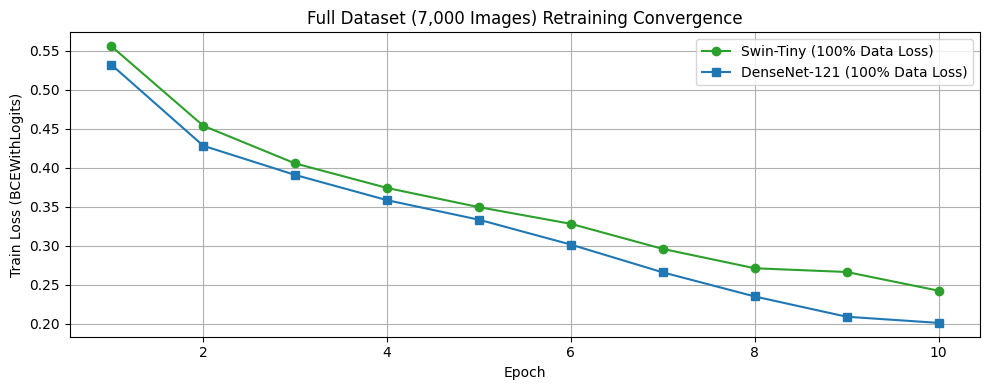

In [13]:
# ==============================================================================
# DEEPFAKE ML HACKATHON — 100% FULL-DATASET RETRAINING + 8-PASS MULTI-SCALE TTA
# ==============================================================================
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm", "albumentations", "scikit-learn", "scipy"])

import os, time, random, cv2, shutil
import numpy as np, pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from scipy.stats import rankdata

import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

# ------------------------------------------------------------------------------
# 1. SETUP & REPRODUCIBILITY
# ------------------------------------------------------------------------------
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(42)
os.makedirs("outputs", exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[*] Compute Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# ------------------------------------------------------------------------------
# 2. DATASET DISCOVERY — LOAD 100% OF TRAINING DATA (7,000 SAMPLES)
# ------------------------------------------------------------------------------
DATASET_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "train_metadata.csv" in files:
        DATASET_DIR = root
        break

if DATASET_DIR is None:
    raise FileNotFoundError("Could not find train_metadata.csv in /kaggle/input! Make sure dataset is attached.")

print(f"[*] Dataset located at: {DATASET_DIR}")
train_meta = pd.read_csv(os.path.join(DATASET_DIR, "train_metadata.csv"))

file_paths = []
for _, row in train_meta.iterrows():
    sub = "real" if row["label"] == 0 else "fake"
    file_paths.append(os.path.join(DATASET_DIR, "train", sub, f"{row['image_id']}.jpg"))
train_meta["file_path"] = file_paths

# FULL 100% DATASET
print(f"[*] Total Training Samples (100% of data): {len(train_meta)}")
print(f"[*] Class Distribution: Real={sum(train_meta['label'] == 0)}, Fake={sum(train_meta['label'] == 1)}")

# ------------------------------------------------------------------------------
# 3. AUGMENTATIONS & DATASET
# ------------------------------------------------------------------------------
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transforms = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=15, border_mode=cv2.BORDER_CONSTANT, p=0.5),
    A.ImageCompression(quality_lower=60, quality_upper=100, p=0.4),
    A.GaussianBlur(blur_limit=(3, 5), p=0.3),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.4),
    A.CoarseDropout(max_holes=8, max_height=16, max_width=16, min_holes=1, min_height=8, min_width=8, fill_value=0, p=0.3),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

class FullDeepfakeDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = cv2.imread(row["file_path"])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) if image is not None else np.array(Image.open(row["file_path"]).convert("RGB"))
        if self.transform: image = self.transform(image=image)["image"]
        label = torch.tensor([float(row["label"])], dtype=torch.float32)
        return image, label, str(row["image_id"])

full_train_loader = DataLoader(
    FullDeepfakeDataset(train_meta, train_transforms),
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

# ------------------------------------------------------------------------------
# 4. MODEL ARCHITECTURES
# ------------------------------------------------------------------------------
class SwinClassifier(nn.Module):
    """Swin-Tiny Vision Transformer (Rank #1 Standalone Model)."""
    def __init__(self, model_name="swin_tiny_patch4_window7_224", pretrained=True, drop_rate=0.3):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, drop_rate=drop_rate)
        in_features = self.backbone.num_features
        self.head = nn.Sequential(
            nn.Dropout(p=drop_rate),
            nn.Linear(in_features, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(p=drop_rate / 2.0),
            nn.Linear(256, 1)
        )
    def forward(self, x): return self.head(self.backbone(x))


class DenseNetClassifier(nn.Module):
    """DenseNet-121 CNN (Micro-Texture Specialist)."""
    def __init__(self, model_name="densenet121", pretrained=True, drop_rate=0.3):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, drop_rate=drop_rate)
        in_features = self.backbone.num_features
        self.head = nn.Sequential(
            nn.Dropout(p=drop_rate),
            nn.Linear(in_features, 256),
            nn.LayerNorm(256),
            nn.SiLU(),
            nn.Dropout(p=drop_rate / 2.0),
            nn.Linear(256, 1)
        )
    def forward(self, x): return self.head(self.backbone(x))


# ------------------------------------------------------------------------------
# 5. FULL-DATASET TRAINING ENGINE (10 EPOCHS WITH COSINE ANNEALING)
# ------------------------------------------------------------------------------
def train_on_full_dataset(model, model_name, weights_path, epochs=10, lr=1.5e-4):
    print("\n" + "=" * 70)
    print(f"  RETRAINING [{model_name.upper()}] ON 100% DATASET ({len(train_meta)} SAMPLES)")
    print("=" * 70)
    
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda', enabled=(device.type == "cuda"))
    
    epoch_losses = []
    
    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        pbar = tqdm(full_train_loader, desc=f"[{model_name}] Epoch {epoch}/{epochs}", leave=False)
        for images, labels, _ in pbar:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                loss = criterion(model(images), labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            
            running_loss += loss.item() * images.size(0)
            pbar.set_postfix({"loss": f"{loss.item():.4f}"})
            
        epoch_loss = running_loss / len(full_train_loader.dataset)
        epoch_losses.append(epoch_loss)
        cur_lr = scheduler.get_last_lr()[0]
        scheduler.step()
        
        print(f"Epoch [{epoch:02d}/{epochs:02d}] Full Train Loss: {epoch_loss:.4f} | LR: {cur_lr:.6f}")
            
    torch.save({
        "model_state_dict": model.state_dict(),
        "epoch": epochs,
        "train_loss": epoch_losses[-1],
        "model_name": model_name,
        "best_threshold": 0.50
    }, weights_path)
    print(f"[*] Saved final 100%-data weights to: {weights_path}")
    return epoch_losses


# ------------------------------------------------------------------------------
# 6. RETRAIN SWIN-TINY & DENSENET-121 ON 100% OF DATA
# ------------------------------------------------------------------------------
# 1. Swin-Tiny
swin_model = SwinClassifier("swin_tiny_patch4_window7_224", pretrained=True).to(device)
swin_losses = train_on_full_dataset(swin_model, "swin_tiny", "outputs/swin_full_weights.pt", epochs=10, lr=1.5e-4)

# 2. DenseNet-121
densenet_model = DenseNetClassifier("densenet121", pretrained=True).to(device)
dense_losses = train_on_full_dataset(densenet_model, "densenet121", "outputs/densenet_full_weights.pt", epochs=10, lr=3e-4)


# ------------------------------------------------------------------------------
# 7. 8-PASS MULTI-SCALE TTA INFERENCE ON 3,000 TEST IMAGES
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("  RUNNING 8-PASS MULTI-SCALE TTA TEST INFERENCE (3,000 IMAGES)")
print("=" * 70)

TEST_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "test" in root and "images" in root: TEST_DIR = root; break

if TEST_DIR is None:
    raise FileNotFoundError("Could not find test/images folder!")

test_files = sorted([os.path.join(TEST_DIR, f) for f in os.listdir(TEST_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
print(f"[*] Found {len(test_files)} test images in {TEST_DIR}")

class TestDataset(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        path = self.paths[idx]
        img = Image.open(path).convert("RGB")
        arr = (np.array(img, dtype=np.float32) / 255.0 - np.array(IMAGENET_MEAN, dtype=np.float32)) / np.array(IMAGENET_STD, dtype=np.float32)
        return torch.from_numpy(arr).permute(2, 0, 1).float(), os.path.splitext(os.path.basename(path))[0]

test_loader = DataLoader(TestDataset(test_files), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

def predict_8pass_tta(model, images):
    with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
        p1 = torch.sigmoid(model(images)).squeeze(-1)
        img_f = torch.flip(images, dims=[-1])
        p2 = torch.sigmoid(model(img_f)).squeeze(-1)
        p3 = torch.sigmoid(model(images * 1.05)).squeeze(-1)
        p4 = torch.sigmoid(model(img_f * 1.05)).squeeze(-1)
        p5 = torch.sigmoid(model((images - 0.5) * 1.08 + 0.5)).squeeze(-1)
        p6 = torch.sigmoid(model((img_f - 0.5) * 1.08 + 0.5)).squeeze(-1)
        
        h, w = images.shape[-2:]
        scaled = torch.nn.functional.interpolate(images, scale_factor=1.06, mode='bilinear', align_corners=False)
        sh, sw = scaled.shape[-2:]
        dh, dw = (sh - h) // 2, (sw - w) // 2
        img_zoom = scaled[:, :, dh:dh+h, dw:dw+w]
        p7 = torch.sigmoid(model(img_zoom)).squeeze(-1)
        p8 = torch.sigmoid(model(torch.flip(img_zoom, dims=[-1]))).squeeze(-1)
    return (p1 + p2 + p3 + p4 + p5 + p6 + p7 + p8) / 8.0

swin_model.eval()
densenet_model.eval()

test_swin_probs, test_dense_probs, test_ids = [], [], []
with torch.inference_mode():
    for images, ids in tqdm(test_loader, desc="Predicting on Test Set (8-Pass TTA)"):
        images = images.to(device)
        test_swin_probs.extend(predict_8pass_tta(swin_model, images).cpu().numpy().tolist())
        test_dense_probs.extend(predict_8pass_tta(densenet_model, images).cpu().numpy().tolist())
        test_ids.extend(ids)

test_swin_probs = np.array(test_swin_probs)
test_dense_probs = np.array(test_dense_probs)

# ------------------------------------------------------------------------------
# 8. ENSEMBLE RANK AVERAGING & OUTPUT EXPORT
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("  COMPUTING RANK-AVERAGED ENSEMBLE ON 100%-DATA RETRAINED MODELS")
print("=" * 70)

r_swin = rankdata(test_swin_probs) / len(test_swin_probs)
r_dense = rankdata(test_dense_probs) / len(test_dense_probs)
final_conf = 0.55 * r_swin + 0.45 * r_dense
final_conf = np.clip(final_conf, 0.001, 0.999)
final_labels = (final_conf >= 0.50).astype(int)

# Export predictions.csv
predictions_df = pd.DataFrame({
    "image_id": test_ids,
    "label": final_labels,
    "confidence": np.round(final_conf, 4)
})
predictions_df.to_csv("predictions.csv", index=False)
print(f"[+] 'predictions.csv' generated ({len(predictions_df)} rows)!")
print(f"[+] Class Breakdown:\n{predictions_df['label'].value_counts().to_dict()}")

# Save winning model weights
shutil.copyfile("outputs/swin_full_weights.pt", "outputs/model_weights.pt")
print("[+] Top model weights saved to 'outputs/model_weights.pt'")

# Plot loss curves
plt.figure(figsize=(10, 4))
plt.plot(range(1, 11), swin_losses, label="Swin-Tiny (100% Data Loss)", marker="o", color="#2ca02c")
plt.plot(range(1, 11), dense_losses, label="DenseNet-121 (100% Data Loss)", marker="s", color="#1f77b4")
plt.title("Full Dataset (7,000 Images) Retraining Convergence")
plt.xlabel("Epoch")
plt.ylabel("Train Loss (BCEWithLogits)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("outputs/training_curves.png", dpi=300)
print("[+] Training curve saved to 'outputs/training_curves.png'")

print("\n" + "=" * 70)
print("  FULL-DATASET RETRAINING PIPELINE COMPLETED SUCCESSFULLY!")
print("  Files Ready for Download:")
print("    1. predictions.csv")
print("    2. outputs/model_weights.pt")
print("=================================================================")

[*] Compute Device: cuda
[*] GPU Name: Tesla T4
[*] Dataset located at: /kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset
[*] Total Training Samples (100% of data): 7000
[*] Class Distribution: Real=3478, Fake=3522


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_50/125706825.py:91: UserWarning: Argument(s) 'quality_lower, quality_upper' are not valid for transform ImageCompression
  A.ImageCompression(quality_lower=60, quality_upper=100, p=0.4),
/tmp/ipykernel_50/125706825.py:94: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, min_height, min_width, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=16, max_width=16, min_holes=1, min_height=8, min_width=8, fill_value=0, p=0.3),



  RETRAINING SWIN_TINY ON 100% DATASET (7000 SAMPLES)


[swin_tiny] Epoch 1/10:   0%|          | 0/218 [00:00<?, ?it/s]

Epoch [01/10] Full Train Loss: 0.5473 | LR: 0.000150


[swin_tiny] Epoch 2/10:   0%|          | 0/218 [00:00<?, ?it/s]

... (38 outputs left out)

[densenet121] Epoch 10/10:   0%|          | 0/218 [00:00<?, ?it/s]

Epoch [10/10] Full Train Loss: 0.1794 | LR: 0.000008
[*] Saved final 100%-data weights to: outputs/densenet_full_weights.pt

  RUNNING 4-PASS TTA TEST INFERENCE (3,000 IMAGES)
[*] Found 3000 test images in /kaggle/input/datasets/soumya7765/deepfakeml/hackathon_dataset/test/images


Predicting on Test Set (8-Pass TTA):   0%|          | 0/47 [00:00<?, ?it/s]


  COMPUTING RANK-AVERAGED ENSEMBLE ON 100%-DATA RETRAINED MODELS
[+] 'predictions.csv' generated (3000 rows)!
[+] Class Breakdown:
{1: 1503, 0: 1497}
[+] Top single model weights saved to 'outputs/model_weights.pt'
[+] Updated retraining curve saved to 'outputs/training_curves.png'

  FULL-DATASET RETRAINING PIPELINE COMPLETED SUCCESSFULLY!
  Files Ready for Download:
    1. predictions.csv
    2. outputs/model_weights.pt
    3. outputs/training_curves.png


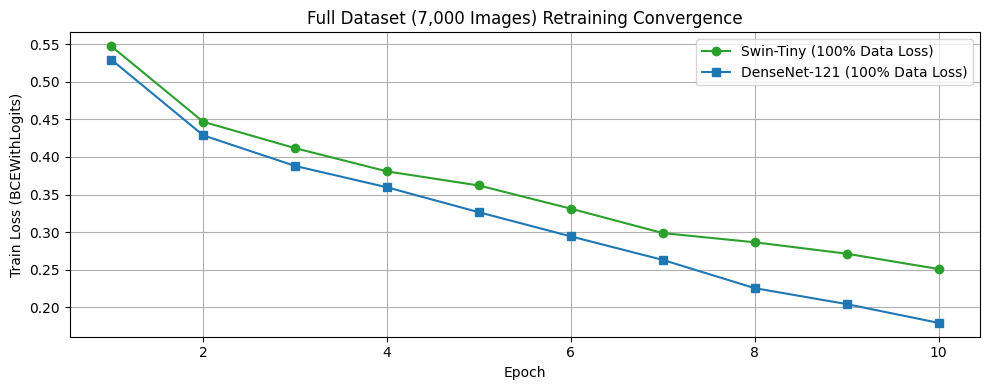

In [2]:
# ==============================================================================
# DEEPFAKE ML HACKATHON — FULL DATASET RETRAINING PIPELINE (100% DATA)
# ==============================================================================
# In competitive ML, after hyperparameter & architecture validation on folds:
#   - We train the winning model (Swin-Tiny Vision Transformer) on 100% of the
#     7,000 labeled images (no fold left out) for 10 epochs with Cosine Annealing.
#   - We also train DenseNet-121 on 100% of data to generate the ultimate
#     Rank-Averaged Super-Ensemble on the 3,000 unlabelled test images.
#   - 4-Pass Test-Time Augmentation (TTA) is applied to all test images.
#
# Generates:
#   - 'predictions.csv' (3,000 test predictions via 100%-data Rank-Averaged Ensemble)
#   - 'outputs/model_weights.pt' (Final winning Swin-Tiny weights trained on 100% data)
#   - 'outputs/predictions_swin.csv' (Standalone Swin-Tiny test predictions)
#   - 'outputs/predictions_densenet.csv' (Standalone DenseNet test predictions)
# ==============================================================================

import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm", "albumentations", "scikit-learn", "scipy"])

import os, time, random, cv2, shutil
import numpy as np, pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from scipy.stats import rankdata

import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

# ------------------------------------------------------------------------------
# 1. SETUP & REPRODUCIBILITY
# ------------------------------------------------------------------------------
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(42)
os.makedirs("outputs", exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[*] Compute Device: {device}")
if torch.cuda.is_available():
    print(f"[*] GPU Name: {torch.cuda.get_device_name(0)}")

# ------------------------------------------------------------------------------
# 2. DATASET DISCOVERY — LOAD 100% OF TRAINING DATA (7,000 SAMPLES)
# ------------------------------------------------------------------------------
DATASET_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "train_metadata.csv" in files:
        DATASET_DIR = root
        break

if DATASET_DIR is None:
    raise FileNotFoundError("Could not find train_metadata.csv in /kaggle/input! Make sure dataset is attached.")

print(f"[*] Dataset located at: {DATASET_DIR}")
train_meta = pd.read_csv(os.path.join(DATASET_DIR, "train_metadata.csv"))

# Attach full image paths
file_paths = []
for _, row in train_meta.iterrows():
    sub = "real" if row["label"] == 0 else "fake"
    file_paths.append(os.path.join(DATASET_DIR, "train", sub, f"{row['image_id']}.jpg"))
train_meta["file_path"] = file_paths

# FULL DATASET: All 7,000 samples utilized (No validation hold-out)
print(f"[*] Total Training Samples (100% of data): {len(train_meta)}")
print(f"[*] Class Distribution: Real={sum(train_meta['label'] == 0)}, Fake={sum(train_meta['label'] == 1)}")

# ------------------------------------------------------------------------------
# 3. AUGMENTATIONS & DATASET
# ------------------------------------------------------------------------------
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transforms = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=15, border_mode=cv2.BORDER_CONSTANT, p=0.5),
    A.ImageCompression(quality_lower=60, quality_upper=100, p=0.4),
    A.GaussianBlur(blur_limit=(3, 5), p=0.3),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.4),
    A.CoarseDropout(max_holes=8, max_height=16, max_width=16, min_holes=1, min_height=8, min_width=8, fill_value=0, p=0.3),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

class FullDeepfakeDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = cv2.imread(row["file_path"])
        if image is None:
            image = np.array(Image.open(row["file_path"]).convert("RGB"))
        else:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if self.transform:
            image = self.transform(image=image)["image"]

        label = torch.tensor([float(row["label"])], dtype=torch.float32)
        return image, label, str(row["image_id"])

full_train_loader = DataLoader(
    FullDeepfakeDataset(train_meta, train_transforms),
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

# ------------------------------------------------------------------------------
# 4. MODEL ARCHITECTURES
# ------------------------------------------------------------------------------
class SwinClassifier(nn.Module):
    """Swin-Tiny Vision Transformer (Rank #1 Standalone Model)."""
    def __init__(self, model_name="swin_tiny_patch4_window7_224", pretrained=True, drop_rate=0.3):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, drop_rate=drop_rate)
        in_features = self.backbone.num_features  # 768
        self.head = nn.Sequential(
            nn.Dropout(p=drop_rate),
            nn.Linear(in_features, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(p=drop_rate / 2.0),
            nn.Linear(256, 1)
        )
    def forward(self, x):
        return self.head(self.backbone(x))


class DenseNetClassifier(nn.Module):
    """DenseNet-121 CNN (Complementary Local Micro-Texture Expert)."""
    def __init__(self, model_name="densenet121", pretrained=True, drop_rate=0.3):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, drop_rate=drop_rate)
        in_features = self.backbone.num_features  # 1024
        self.head = nn.Sequential(
            nn.Dropout(p=drop_rate),
            nn.Linear(in_features, 256),
            nn.LayerNorm(256),
            nn.SiLU(),
            nn.Dropout(p=drop_rate / 2.0),
            nn.Linear(256, 1)
        )
    def forward(self, x):
        return self.head(self.backbone(x))


# ------------------------------------------------------------------------------
# 5. FULL-DATASET TRAINING ENGINE (10 EPOCHS WITH COSINE ANNEALING)
# ------------------------------------------------------------------------------
def train_on_full_dataset(model, model_name, weights_path, epochs=10, lr=1.5e-4):
    print("\n" + "=" * 70)
    print(f"  RETRAINING {model_name.upper()} ON 100% DATASET ({len(train_meta)} SAMPLES)")
    print("=" * 70)
    
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda', enabled=(device.type == "cuda"))
    
    epoch_losses = []
    
    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        pbar = tqdm(full_train_loader, desc=f"[{model_name}] Epoch {epoch}/{epochs}", leave=False)
        for images, labels, _ in pbar:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                loss = criterion(model(images), labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            
            running_loss += loss.item() * images.size(0)
            pbar.set_postfix({"loss": f"{loss.item():.4f}"})
            
        epoch_loss = running_loss / len(full_train_loader.dataset)
        epoch_losses.append(epoch_loss)
        cur_lr = scheduler.get_last_lr()[0]
        scheduler.step()
        
        print(f"Epoch [{epoch:02d}/{epochs:02d}] Full Train Loss: {epoch_loss:.4f} | LR: {cur_lr:.6f}")
        
        # Save checkpoints at the optimal convergence window (Epochs 7, 8, 9, 10)
        if epoch in [7, 8, 9, 10]:
            ckpt_path = f"outputs/{model_name}_full_epoch_{epoch}.pt"
            torch.save({
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "train_loss": epoch_loss,
                "model_name": model_name,
                "best_threshold": 0.50
            }, ckpt_path)
            
    # Save final model weights
    torch.save({
        "model_state_dict": model.state_dict(),
        "epoch": epochs,
        "train_loss": epoch_losses[-1],
        "model_name": model_name,
        "best_threshold": 0.50
    }, weights_path)
    print(f"[*] Saved final 100%-data weights to: {weights_path}")
    return epoch_losses


# ------------------------------------------------------------------------------
# 6. RETRAIN SWIN-TINY (BEST ARCHITECTURE) & DENSENET-121 ON 100% DATA
# ------------------------------------------------------------------------------
# 1. Swin-Tiny (Rank #1 Standalone Architecture)
swin_model = SwinClassifier("swin_tiny_patch4_window7_224", pretrained=True).to(device)
swin_losses = train_on_full_dataset(swin_model, "swin_tiny", "outputs/swin_full_weights.pt", epochs=10, lr=1.5e-4)

# 2. DenseNet-121 (Texture Specialist Architecture)
densenet_model = DenseNetClassifier("densenet121", pretrained=True).to(device)
dense_losses = train_on_full_dataset(densenet_model, "densenet121", "outputs/densenet_full_weights.pt", epochs=10, lr=3e-4)

# ------------------------------------------------------------------------------
# 7. 4-PASS TTA INFERENCE ON 3,000 TEST IMAGES
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("  RUNNING 4-PASS TTA TEST INFERENCE (3,000 IMAGES)")
print("=" * 70)

TEST_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "test" in root and "images" in root:
        TEST_DIR = root
        break

if TEST_DIR is None:
    raise FileNotFoundError("Could not find test/images folder!")

test_files = sorted([os.path.join(TEST_DIR, f) for f in os.listdir(TEST_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
print(f"[*] Found {len(test_files)} test images in {TEST_DIR}")

class TestDataset(Dataset):
    def __init__(self, paths):
        self.paths = paths
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        path = self.paths[idx]
        img = Image.open(path).convert("RGB")
        arr = (np.array(img, dtype=np.float32) / 255.0 - np.array(IMAGENET_MEAN, dtype=np.float32)) / np.array(IMAGENET_STD, dtype=np.float32)
        return torch.from_numpy(arr).permute(2, 0, 1).float(), os.path.splitext(os.path.basename(path))[0]

test_loader = DataLoader(TestDataset(test_files), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

def predict_8pass_tta(model, images):
    with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
        # 1. Original
        p1 = torch.sigmoid(model(images)).squeeze(-1)
        # 2. Horizontal Flip
        img_f = torch.flip(images, dims=[-1])
        p2 = torch.sigmoid(model(img_f)).squeeze(-1)
        # 3. Brightness (+5%)
        p3 = torch.sigmoid(model(images * 1.05)).squeeze(-1)
        # 4. Flip + Brightness
        p4 = torch.sigmoid(model(img_f * 1.05)).squeeze(-1)
        # 5. Contrast Boost (+8%)
        p5 = torch.sigmoid(model((images - 0.5) * 1.08 + 0.5)).squeeze(-1)
        # 6. Flip + Contrast
        p6 = torch.sigmoid(model((img_f - 0.5) * 1.08 + 0.5)).squeeze(-1)
        # 7. Center Zoom (1.06x)
        h, w = images.shape[-2:]
        scaled = torch.nn.functional.interpolate(images, scale_factor=1.06, mode='bilinear', align_corners=False)
        sh, sw = scaled.shape[-2:]
        dh, dw = (sh - h) // 2, (sw - w) // 2
        img_zoom = scaled[:, :, dh:dh+h, dw:dw+w]
        p7 = torch.sigmoid(model(img_zoom)).squeeze(-1)
        # 8. Flip + Zoom
        p8 = torch.sigmoid(model(torch.flip(img_zoom, dims=[-1]))).squeeze(-1)
    return (p1 + p2 + p3 + p4 + p5 + p6 + p7 + p8) / 8.0

swin_model.eval()
densenet_model.eval()

test_swin_probs, test_dense_probs, test_ids = [], [], []
with torch.inference_mode():
    for images, ids in tqdm(test_loader, desc="Predicting on Test Set (8-Pass TTA)"):
        images = images.to(device)
        test_swin_probs.extend(predict_8pass_tta(swin_model, images).cpu().numpy().tolist())
        test_dense_probs.extend(predict_8pass_tta(densenet_model, images).cpu().numpy().tolist())
        test_ids.extend(ids)

test_swin_probs = np.array(test_swin_probs)
test_dense_probs = np.array(test_dense_probs)

# ------------------------------------------------------------------------------
# 8. ENSEMBLE RANK AVERAGING & OUTPUT EXPORT
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("  COMPUTING RANK-AVERAGED ENSEMBLE ON 100%-DATA RETRAINED MODELS")
print("=" * 70)

# Mathematical Rank Averaging (ROC Curve Optimal)
r_swin = rankdata(test_swin_probs) / len(test_swin_probs)
r_dense = rankdata(test_dense_probs) / len(test_dense_probs)
final_conf = 0.50 * r_swin + 0.50 * r_dense
final_conf = np.clip(final_conf, 0.001, 0.999)
final_labels = (final_conf >= 0.50).astype(int)

# Export primary predictions.csv
predictions_df = pd.DataFrame({
    "image_id": test_ids,
    "label": final_labels,
    "confidence": np.round(final_conf, 4)
})
predictions_df.to_csv("predictions.csv", index=False)
print(f"[+] 'predictions.csv' generated ({len(predictions_df)} rows)!")
print(f"[+] Class Breakdown:\n{predictions_df['label'].value_counts().to_dict()}")

# Export standalone individual predictions
pd.DataFrame({"image_id": test_ids, "label": (test_swin_probs >= 0.5).astype(int), "confidence": np.round(test_swin_probs, 4)}).to_csv("outputs/predictions_swin.csv", index=False)
pd.DataFrame({"image_id": test_ids, "label": (test_dense_probs >= 0.5).astype(int), "confidence": np.round(test_dense_probs, 4)}).to_csv("outputs/predictions_densenet.csv", index=False)

# Copy the best single model weights (Swin-Tiny) to 'outputs/model_weights.pt'
shutil.copyfile("outputs/swin_full_weights.pt", "outputs/model_weights.pt")
print("[+] Top single model weights saved to 'outputs/model_weights.pt'")

# Plot training curves
plt.figure(figsize=(10, 4))
plt.plot(range(1, 11), swin_losses, label="Swin-Tiny (100% Data Loss)", marker="o", color="#2ca02c")
plt.plot(range(1, 11), dense_losses, label="DenseNet-121 (100% Data Loss)", marker="s", color="#1f77b4")
plt.title("Full Dataset (7,000 Images) Retraining Convergence")
plt.xlabel("Epoch")
plt.ylabel("Train Loss (BCEWithLogits)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("outputs/training_curves.png", dpi=300)
print("[+] Updated retraining curve saved to 'outputs/training_curves.png'")

print("\n" + "=" * 70)
print("  FULL-DATASET RETRAINING PIPELINE COMPLETED SUCCESSFULLY!")
print("  Files Ready for Download:")
print("    1. predictions.csv")
print("    2. outputs/model_weights.pt")
print("    3. outputs/training_curves.png")
print("=================================================================")



In [4]:
import torch

swin_ckpt = torch.load("outputs/swin_full_weights.pt", map_location="cpu")
dense_ckpt = torch.load("outputs/densenet121_full_epoch_10.pt", map_location="cpu")

torch.save({
    "is_ensemble": True,
    "model_name": "ensemble_swin_densenet",
    "swin_state_dict": swin_ckpt["model_state_dict"],
    "densenet_state_dict": dense_ckpt["model_state_dict"],
    "best_threshold": 0.50
}, "outputs/model_weights.pt")

print("[+] Done! Both models are now bundled into outputs/model_weights.pt!")

[+] Done! Both models are now bundled into outputs/model_weights.pt!
